# Smart Calibration Stability Management — AI4I 2020 (revised, single source of truth)

**Task actually solved here:** prediction of the AI4I `Machine failure` label from process variables.
**What is *not* claimed:** AI4I has **no** calibration-drift / calibration-failure ground truth. Engineered variables
(thermal gradient, torque deviation, speed deviation, combined stress index, ...) are **process-stability / calibration-relevant proxy features**, not validated calibration-drift measurements.

**Product Type.** `Type` ∈ {L, M, H} denotes **product-quality variants (product types)**. They are *not* independent suppliers, and nothing in this notebook treats them as such.

**Design principles (apply to every cell below)**
1. Split first, then fit anything data-derived (scalers, normalisation limits, group statistics, rolling parameters, SMOTE, threshold) on training data only.
2. The held-out test set is used once, for final evaluation (and clearly labelled diagnostics).
3. Every number, table and figure is computed from objects in this notebook. Nothing is typed in by hand (the only literals are *dataset facts* in the audit section that are asserted against the data).
4. Outputs: `outputs/tables/*.csv`, `outputs/figures/*.png|pdf`.

**Run order:** top to bottom, no manual edits needed. Requires `data.csv` (AI4I 2020) next to the notebook.
Optional dependencies: `tensorflow` (LSTM section) and `shap` (SHAP figure); both are skipped gracefully if absent.

In [1]:
# %pip install -q imbalanced-learn xgboost seaborn      # uncomment if needed (tensorflow / shap are optional)

import os, sys, platform, warnings, time, random, inspect
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import chi2_contingency, chi2 as chi2_dist

import sklearn, imblearn, xgboost, joblib
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (confusion_matrix, f1_score, recall_score, precision_score, matthews_corrcoef,
                             roc_auc_score, average_precision_score, roc_curve, precision_recall_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, IsolationForest
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_class_weight
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")

# ---------------- reproducibility ----------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)

# ---------------- output folders ----------------
OUT_DIR = Path("outputs"); FIG_DIR = OUT_DIR / "figures"; TAB_DIR = OUT_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True); TAB_DIR.mkdir(parents=True, exist_ok=True)

# ---------------- global constants (column names / settings, not results) ----------------
TARGET = "Machine failure"
LEAKAGE_COLS = ["TWF", "HDF", "PWF", "OSF", "RNF"]      # components of the target -> never predictors
ID_COLS = ["UDI", "Product ID"]                           # identifiers -> never predictors
RAW5 = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
TYPE_COL = "Type_encoded"
SCORE_COL = "type_process_stability_score"
ENG_FEATURES = ["thermal_gradient", "mechanical_power", "thermal_efficiency", "tool_wear_severity",
                "combined_stress_index", "torque_deviation", "speed_deviation"]
ALL14 = RAW5 + [TYPE_COL] + ENG_FEATURES + [SCORE_COL]
ROLL_WINDOW = 100
TEST_SIZE = 0.20
DEFAULT_THRESHOLD = 0.5
N_BOOT = 2000
SD_DDOF = 0          # SD across folds is the population SD (ddof=0); stated wherever SDs are reported
METRICS = ["F1", "Recall", "Precision", "MCC", "ROC_AUC", "PR_AUC"]

# ---------------- plotting style ----------------
plt.rcParams.update({"font.family": "serif", "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "figure.dpi": 100, "savefig.dpi": 300})
PAL = ["#4d4d4d", "#1f6f8b", "#c8553d", "#8f8f8f", "#6a994e", "#a68a64", "#3b3b98"]

# ---------------- helpers ----------------
FIG_LOG, TABLES = [], {}
CHECK_COUNT = 0

def chk(cond, msg):
    """Consistency check: raises AssertionError with message if cond is False."""
    global CHECK_COUNT
    if not bool(cond):
        raise AssertionError("CONSISTENCY CHECK FAILED: " + msg)
    CHECK_COUNT += 1

def save_fig(fig, name):
    """Save PNG (300 dpi) + PDF (vector); refuse any figure containing forbidden terminology."""
    txt = " ".join(t.get_text() for t in fig.findobj(mpl.text.Text)).lower()
    assert "supplier" not in txt, f"forbidden terminology in figure {name}"
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    FIG_LOG.append(name)
    plt.show()

def save_table(df, name, index=False):
    df.to_csv(TAB_DIR / f"{name}.csv", index=index)
    TABLES[name] = df.copy()
    return df

def evaluate(y_true, y_pred, y_score):
    """All metrics + confusion-matrix cells, computed directly from predictions."""
    y_true = np.asarray(y_true).astype(int); y_pred = np.asarray(y_pred).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"F1": f1_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "MCC": matthews_corrcoef(y_true, y_pred),
            "ROC_AUC": roc_auc_score(y_true, y_score),
            "PR_AUC": average_precision_score(y_true, y_score),
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}

def best_f1_threshold(y_true, score):
    """F1-optimal threshold on the PR curve of (y_true, score). Returns (threshold, F1)."""
    pr, rc, th = precision_recall_curve(y_true, score)
    f = 2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12)
    k = int(np.argmax(f))
    return float(th[k]), float(f[k])

def wilson_ci(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

def plot_cm(ax, cm, title):
    cm = np.asarray(cm)
    ax.imshow(cm, cmap="Greys", vmin=0, vmax=cm.max() * 1.6)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:d}", ha="center", va="center", fontsize=13,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["No failure", "Failure"]); ax.set_yticklabels(["No failure", "Failure"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Observed"); ax.set_title(title); ax.grid(False)

print("Setup complete | seed =", RANDOM_STATE)

Setup complete | seed = 42


# 1. Dataset Interpretation and Reproducibility Audit

This section loads AI4I 2020, verifies its basic facts and fixes the interpretation of `Type`.

* `Type` ∈ {L, M, H} = **product-quality variants (product types)**. They are not suppliers.
* The target is `Machine failure`. There is no calibration-drift label.
* The `LabelEncoder` maps classes alphabetically: **H → 0, L → 1, M → 2**.

In [2]:
DATA_CANDIDATES = ["data.csv", "ai4i2020.csv", "/mnt/data/data.csv", "/content/data.csv"]
DATA_PATH = next((p for p in DATA_CANDIDATES if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("AI4I file not found. Put it next to the notebook as data.csv. Tried: " + str(DATA_CANDIDATES))

raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
raw.columns = [c.strip() for c in raw.columns]
print("Data file:", DATA_PATH)
print("Dataset dimensions (rows, columns):", raw.shape)

# ---- target ----
n_total = len(raw)
n_fail = int(raw[TARGET].sum())
print("\nTarget counts:", raw[TARGET].value_counts().sort_index().to_dict())
print(f"Failure prevalence: {n_fail}/{n_total} = {n_fail / n_total:.4f} ({100 * n_fail / n_total:.2f}%)")

# ---- Type counts and label encoding (class label mapping only; no data-derived statistic) ----
print("\nType counts:", raw["Type"].value_counts().to_dict())
le = LabelEncoder().fit(raw["Type"])
print("LabelEncoder.classes_ :", list(le.classes_))
TYPE_CODE_MAP = {str(c): int(k) for c, k in zip(le.classes_, le.transform(le.classes_))}
TYPE_NAME_MAP = {v: k for k, v in TYPE_CODE_MAP.items()}          # {0: 'H', 1: 'L', 2: 'M'}
print("Encoding:", ", ".join(f"{k} -> {v}" for k, v in TYPE_CODE_MAP.items()))
assert TYPE_CODE_MAP == {"H": 0, "L": 1, "M": 2}, "unexpected label encoding"

# ---- confirm the documented dataset facts (these are facts about the data file, asserted not assumed) ----
type_counts = raw["Type"].value_counts()
assert (type_counts["L"], type_counts["M"], type_counts["H"]) == (6000, 2997, 1003), "Type counts differ from the AI4I reference"
print("\nConfirmed Type counts: L =", type_counts["L"], "| M =", type_counts["M"], "| H =", type_counts["H"])

# ---- failures by Type ----
type_tbl = (raw.groupby("Type")[TARGET].agg(n="size", failures="sum", failure_rate="mean")
              .reindex(["H", "L", "M"]))
type_tbl["failure_rate"] = type_tbl["failures"] / type_tbl["n"]
lo_hi = [wilson_ci(int(r.failures), int(r.n)) for r in type_tbl.itertuples()]
type_tbl["ci95_low"] = [a for a, b in lo_hi]; type_tbl["ci95_high"] = [b for a, b in lo_hi]
print("\nMachine failures by product Type:")
display(type_tbl.round(4))
assert type_tbl.loc["H", "failures"] == 21 and type_tbl.loc["L", "failures"] == 235 and type_tbl.loc["M", "failures"] == 83, \
    "failure counts by Type differ from the AI4I reference"

# ---- chi-square test of Type x Machine failure ----
ct = pd.crosstab(raw["Type"], raw[TARGET])
chi2_stat, chi2_p, chi2_dof, _ = chi2_contingency(ct)
cramers_v = float(np.sqrt(chi2_stat / (ct.values.sum() * (min(ct.shape) - 1))))
print(f"\nChi-square (Type x Machine failure): chi2 = {chi2_stat:.3f}, dof = {chi2_dof}, p = {chi2_p:.6f}, Cramer's V = {cramers_v:.3f}")
assert abs(chi2_p - 0.001032) < 2e-5, "chi-square p-value differs from the AI4I reference"

# ---- predictor set: leakage / identifier columns are excluded by construction ----
PREDICTORS_RAW = RAW5 + [TYPE_COL]
df_model = raw[RAW5 + [TARGET]].copy()
df_model[TYPE_COL] = le.transform(raw["Type"])          # row order preserved (index 0..N-1 = original file order)
assert not (set(PREDICTORS_RAW) & set(LEAKAGE_COLS + ID_COLS + [TARGET])), "leakage/identifier/target column among predictors"
print("\nExcluded from all predictor sets:", LEAKAGE_COLS + ID_COLS + [TARGET])
print("Raw predictors:", PREDICTORS_RAW)

Data file: data.csv
Dataset dimensions (rows, columns): (10000, 14)

Target counts: {0: 9661, 1: 339}
Failure prevalence: 339/10000 = 0.0339 (3.39%)

Type counts: {'L': 6000, 'M': 2997, 'H': 1003}
LabelEncoder.classes_ : ['H', 'L', 'M']
Encoding: H -> 0, L -> 1, M -> 2

Confirmed Type counts: L = 6000 | M = 2997 | H = 1003

Machine failures by product Type:


,n,failures,failure_rate,ci95_low,ci95_high
Type,,,,,
H,1003,21,0.0209,0.0137,0.0318
L,6000,235,0.0392,0.0345,0.0444
M,2997,83,0.0277,0.0224,0.0342



Chi-square (Type x Machine failure): chi2 = 13.752, dof = 2, p = 0.001032, Cramer's V = 0.037

Excluded from all predictor sets: ['TWF', 'HDF', 'PWF', 'OSF', 'RNF', 'UDI', 'Product ID', 'Machine failure']
Raw predictors: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_encoded']


**Interpretation.** The chi-square test shows an *association between product Type and machine failure* in this simulated dataset
(failure rate is highest for L and lowest for H). This says nothing about supplier quality — `Type` is a product-quality variant.
The effect size (Cramér's V) is small.

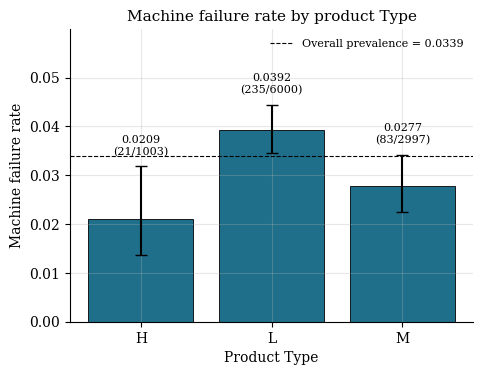

In [3]:
# Figure 1 - machine failure rate by product Type (from the dataframe; Wilson 95% intervals)
fig, ax = plt.subplots(figsize=(5.2, 3.8))
x = np.arange(len(type_tbl))
err = np.vstack([type_tbl["failure_rate"] - type_tbl["ci95_low"], type_tbl["ci95_high"] - type_tbl["failure_rate"]])
ax.bar(x, type_tbl["failure_rate"], yerr=err, capsize=4, color=PAL[1], edgecolor="black", linewidth=0.6)
for i, r in enumerate(type_tbl.itertuples()):
    ax.text(i, r.ci95_high + 0.002, f"{r.failure_rate:.4f}\n({int(r.failures)}/{int(r.n)})", ha="center", va="bottom", fontsize=8)
ax.axhline(n_fail / n_total, color="black", ls="--", lw=0.8, label=f"Overall prevalence = {n_fail / n_total:.4f}")
ax.set_xticks(x); ax.set_xticklabels([f"{t}" for t in type_tbl.index])
ax.set_xlabel("Product Type"); ax.set_ylabel("Machine failure rate")
ax.set_title("Machine failure rate by product Type"); ax.legend(frameon=False, fontsize=8)
ax.set_ylim(0, type_tbl["ci95_high"].max() * 1.35)
save_fig(fig, "fig01_failure_rate_by_product_type")

# 2. Leakage-safe split

The stratified 80/20 split (`random_state=42`) is performed **before** any data-derived transformation is fitted.
From this point the test set (`Xte`, `yte`) is used only for final evaluation.

In [4]:
X_all = df_model[PREDICTORS_RAW]
y_all = df_model[TARGET]

Xtr, Xte, ytr, yte = train_test_split(X_all, y_all, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_all)
train_idx, test_idx = Xtr.index.values.copy(), Xte.index.values.copy()

print(f"Train: {Xtr.shape} | failures = {int(ytr.sum())} ({ytr.mean():.4f})")
print(f"Test : {Xte.shape} | failures = {int(yte.sum())} ({yte.mean():.4f})")
print("Test-set Type counts:", Xte[TYPE_COL].map(TYPE_NAME_MAP).value_counts().to_dict())

# ---- leakage guards ----
assert len(set(train_idx) & set(test_idx)) == 0, "train/test overlap"
assert len(train_idx) + len(test_idx) == len(raw) and set(train_idx) | set(test_idx) == set(raw.index)
assert abs(len(test_idx) / len(raw) - TEST_SIZE) < 1e-9
assert abs(ytr.mean() - yte.mean()) < 5e-4, "split is not stratified"
assert not (set(Xtr.columns) & set(LEAKAGE_COLS)), "leakage columns in training predictors"
assert TARGET not in Xtr.columns and TARGET not in Xte.columns
print("Split checks passed: disjoint, exhaustive, stratified, no leakage columns among predictors.")

Train: (8000, 6) | failures = 271 (0.0339)
Test : (2000, 6) | failures = 68 (0.0340)
Test-set Type counts: {'L': 1170, 'M': 616, 'H': 214}
Split checks passed: disjoint, exhaustive, stratified, no leakage columns among predictors.


# 3. Sequential Structure Audit

Rolling-window, lagged and LSTM analyses implicitly treat file row order as time. This section tests whether that assumption is plausible
**before** any rolling/lag/LSTM feature is used. It is purely descriptive (no model is fitted).

In [6]:
seq_vars = {"Torque": "Torque [Nm]", "Rotational speed": "Rotational speed [rpm]",
            "Process temperature": "Process temperature [K]",
            "Air temperature": "Air temperature [K]", "Tool wear": "Tool wear [min]",
            "Machine failure": TARGET}
seq_audit = pd.DataFrame({"Variable": list(seq_vars.keys()),
                          "lag1_autocorrelation": [raw[c].autocorr(lag=1) for c in seq_vars.values()]})
display(seq_audit.round(3))

types_arr = raw["Type"].values
type_change_share = float((types_arr[1:] != types_arr[:-1]).mean())
p_type = raw["Type"].value_counts(normalize=True)
expected_change_random = float(1 - (p_type ** 2).sum())           # expected share if Types were assigned to rows at random

# --- FIX: use pandas shift instead of np.r_ (np.r_ treats strings as slice directives) ---
types_series = pd.Series(types_arr)
run_id = (types_series != types_series.shift()).cumsum()
run_len = run_id.value_counts()

print(f"Share of adjacent rows whose Type changes : {type_change_share:.3f}")
print(f"Expected share if Type were assigned at random to rows: {expected_change_random:.3f}")
print(f"Mean length of contiguous same-Type runs   : {run_len.mean():.2f} rows (max {run_len.max()})")

,Variable,lag1_autocorrelation
0,Torque,0.005
1,Rotational speed,0.008
2,Process temperature,0.999
3,Air temperature,0.999
4,Tool wear,0.931
5,Machine failure,0.053


Share of adjacent rows whose Type changes : 0.536
Expected share if Type were assigned at random to rows: 0.540
Mean length of contiguous same-Type runs   : 1.86 rows (max 22)


**Interpretation (cautious).** Process and air temperature (and, to a lesser extent, tool wear) are strongly autocorrelated in row order, whereas torque, rotational speed and the failure label are almost uncorrelated from one row to the next.
The product Type changes between adjacent rows at roughly the rate expected if Types were assigned to rows at random. The row order therefore looks like a mixture of smooth and non-sequential variables,
rather than the trajectory of a single machine.

**The AI4I row order does not establish that consecutive observations belong to one physical machine trajectory. Therefore, rolling, lagged, and LSTM analyses based solely on row adjacency are exploratory and cannot be interpreted as validated temporal degradation trajectories.**

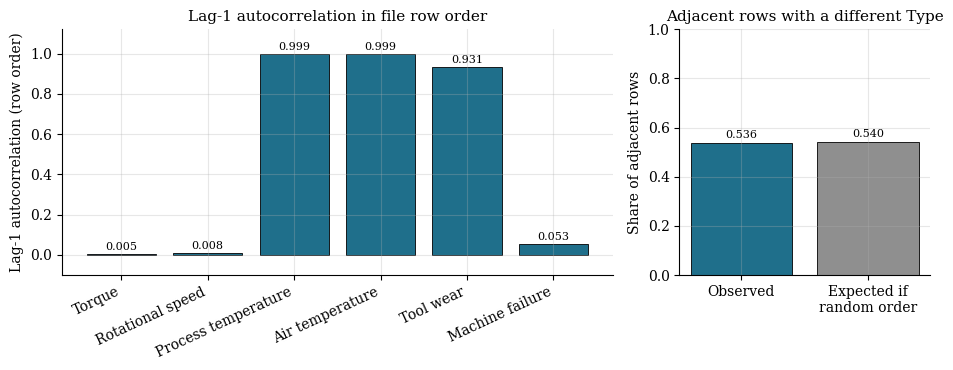

In [7]:
# Figure 13 - sequential audit
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
ax.bar(seq_audit["Variable"], seq_audit["lag1_autocorrelation"], color=PAL[1], edgecolor="black", linewidth=0.6)
for i, v in enumerate(seq_audit["lag1_autocorrelation"]):
    ax.text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=8)
ax.set_ylabel("Lag-1 autocorrelation (row order)"); ax.set_ylim(-0.1, 1.12)
ax.set_title("Lag-1 autocorrelation in file row order"); plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
ax = axes[1]
ax.bar(["Observed", "Expected if\nrandom order"], [type_change_share, expected_change_random], color=[PAL[1], PAL[3]], edgecolor="black", linewidth=0.6)
for i, v in enumerate([type_change_share, expected_change_random]):
    ax.text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=8)
ax.set_ylim(0, 1); ax.set_ylabel("Share of adjacent rows"); ax.set_title("Adjacent rows with a different Type")
fig.tight_layout()
save_fig(fig, "fig13_sequential_structure_audit")

# 4. Engineered process-stability features and the Type-associated stability score

All features below are **engineered process-stability / calibration-relevant proxy features**. None is a direct measurement of calibration drift.

| Feature | Computation | Parameters fitted on training data only |
|---|---|---|
| `thermal_gradient` | Process temperature − Air temperature [K] | – |
| `mechanical_power` | Rotational speed [rpm] × Torque [Nm] (proportional to shaft power; the constant 2π/60 is irrelevant after standardisation) | – |
| `thermal_efficiency` | `mechanical_power / (Process temperature + 1)`. A **heuristic power-to-process-temperature ratio** (rpm·Nm/K); it is not a thermodynamic efficiency and is kept only as a heuristic ratio | – |
| `tool_wear_severity` | Tool wear / max(Tool wear) — a rescaling of tool wear | training max of tool wear |
| `combined_stress_index` | `thermal_gradient × tool_wear_severity × (speed / max speed)` | training max of tool wear and of speed |
| `torque_deviation` | Torque − trailing mean of the previous 100 rows (min_periods = 1) | rolling window evaluated **within each split/fold** (no information crosses splits) |
| `speed_deviation` | Speed − trailing mean of the previous 100 rows | same |
| `type_process_stability_score` | Per Type: standard deviations of tool wear, torque_deviation, speed_deviation and thermal_gradient; min–max normalised across Types, inverted (1 − x), averaged | the per-Type statistics and normalisation limits (training data only), then mapped unchanged to validation/test rows |

**Rolling features are row-adjacency based** and are therefore exploratory (see the Sequential Structure Audit). The target is never used to build any predictor.
`tool_wear_severity` is a linear rescaling of `Tool wear [min]`, and `type_process_stability_score` is constant within each Type; both redundancies are examined below.
SMOTE treats every column (including the discrete Type code and the score) as continuous, so synthetic training rows can carry intermediate values.

In [8]:
class ProcessFeatureBuilder(TransformerMixin, BaseEstimator):
    """Builds engineered process-stability features from the 5 raw sensors + Type code.

    fit(X)      : learns normalisation maxima and the per-Type stability statistics from X ONLY (y is ignored).
    transform(X): computes features for X; rolling statistics use only rows of the X passed in (never other splits).
    Because it is a pipeline step, cross-validation refits it inside every training fold.
    """
    STABILITY_INPUTS = ["Tool wear [min]", "torque_deviation", "speed_deviation", "thermal_gradient"]

    def __init__(self, window=ROLL_WINDOW):
        self.window = window

    def _rolling_dev(self, X, col):
        s = X[col].sort_index()                                   # file row order inside this batch
        return (s - s.rolling(self.window, min_periods=1).mean()).reindex(X.index)

    def _compute(self, X):
        out = X[RAW5 + [TYPE_COL]].copy()
        t_air, t_proc = X["Air temperature [K]"], X["Process temperature [K]"]
        rpm, tq, wear = X["Rotational speed [rpm]"], X["Torque [Nm]"], X["Tool wear [min]"]
        out["thermal_gradient"] = t_proc - t_air
        out["mechanical_power"] = rpm * tq
        out["thermal_efficiency"] = out["mechanical_power"] / (t_proc + 1.0)
        out["tool_wear_severity"] = wear / self.wear_max_
        out["combined_stress_index"] = out["thermal_gradient"] * out["tool_wear_severity"] * (rpm / self.rpm_max_)
        out["torque_deviation"] = self._rolling_dev(X, "Torque [Nm]")
        out["speed_deviation"] = self._rolling_dev(X, "Rotational speed [rpm]")
        for code_, name_ in TYPE_NAME_MAP.items():                  # one-hot (diagnostic use only)
            out[f"Type_is_{name_}"] = (X[TYPE_COL] == code_).astype(int)
        return out

    def fit(self, X, y=None):
        self.fit_index_ = np.asarray(X.index)
        self.wear_max_ = float(X["Tool wear [min]"].max())
        self.rpm_max_ = float(X["Rotational speed [rpm]"].max())
        E = self._compute(X)
        stds = E.groupby(TYPE_COL)[self.STABILITY_INPUTS].std()
        span = (stds.max() - stds.min()).replace(0, np.nan)
        norm = ((stds - stds.min()) / span).fillna(0.0)
        stability = (1.0 - norm).mean(axis=1)                       # lower variability -> higher stability
        self.group_std_ = stds
        self.score_map_ = {int(k): float(v) for k, v in stability.items()}
        return self

    def transform(self, X):
        out = self._compute(X)
        out[SCORE_COL] = out[TYPE_COL].map(self.score_map_)
        if out[SCORE_COL].isna().any():
            raise ValueError("Type present at transform time was not seen when fitting the score map")
        return out


class ColumnSelector(TransformerMixin, BaseEstimator):
    """Selects named columns from the feature DataFrame and returns a float array."""
    def __init__(self, columns=None):
        self.columns = columns
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X[list(self.columns)].to_numpy(dtype=float)


def make_xgb():
    return XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=4)

def make_pipe(clf, cols=None, smote=True):
    """Leakage-safe pipeline: features(fit on fold-train) -> select -> SMOTE(fold-train only) -> scaler -> classifier."""
    steps = [("fe", ProcessFeatureBuilder()), ("sel", ColumnSelector(list(cols) if cols is not None else ALL14))]
    if smote:
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps += [("sc", StandardScaler()), ("clf", clf)]
    return ImbPipeline(steps)

def proba_from_features(model, F):
    """Score a feature DataFrame (output of the fitted 'fe' step) with the fitted selector/scaler/classifier."""
    A = model.named_steps["sc"].transform(model.named_steps["sel"].transform(F))
    return model.named_steps["clf"].predict_proba(A)[:, 1]

print("Pipeline components defined.")

Pipeline components defined.


In [9]:
# Fit the feature builder on TRAINING data only (descriptive inspection; the test set is not transformed here)
fe_main = ProcessFeatureBuilder().fit(Xtr)
Ftr = fe_main.transform(Xtr)

assert set(fe_main.fit_index_) == set(train_idx) and not (set(fe_main.fit_index_) & set(test_idx)), "test rows used in fitting"
# Machine failure is never an input: fitting with the true labels or with shuffled labels gives identical parameters
fe_true = ProcessFeatureBuilder().fit(Xtr, ytr)
fe_shuf = ProcessFeatureBuilder().fit(Xtr, pd.Series(np.random.RandomState(0).permutation(ytr.values), index=ytr.index))
assert fe_true.score_map_ == fe_shuf.score_map_ == fe_main.score_map_
assert (fe_true.wear_max_, fe_true.rpm_max_) == (fe_shuf.wear_max_, fe_shuf.rpm_max_)
assert TARGET not in Ftr.columns and not (set(ALL14) & set(LEAKAGE_COLS + [TARGET]))
print("Leakage checks passed: feature parameters were fitted on", len(fe_main.fit_index_), "training rows only and do not depend on the target.")

print("\nNormalisation limits (training): max tool wear =", fe_main.wear_max_, "| max speed =", fe_main.rpm_max_)
print("\nPer-Type standard deviations used for the score (training data):")
display(fe_main.group_std_.rename(index=TYPE_NAME_MAP).round(4))

# ---- explicit inspection of the Type dependency of the score ----
score_tbl = pd.DataFrame({"Type_encoded": list(fe_main.score_map_.keys()), SCORE_COL: list(fe_main.score_map_.values())})
score_tbl.insert(0, "Type", score_tbl["Type_encoded"].map(TYPE_NAME_MAP))
print("\nScore assigned to each Type (fitted on training data):")
display(score_tbl.round(4))

n_unique_score = int(Ftr[SCORE_COL].nunique())
n_unique_type = int(Ftr[TYPE_COL].nunique())
grp_mean = Ftr.groupby(TYPE_COL)[SCORE_COL].transform("mean")
eta_sq = float(1 - ((Ftr[SCORE_COL] - grp_mean) ** 2).sum() / ((Ftr[SCORE_COL] - Ftr[SCORE_COL].mean()) ** 2).sum())
max_within_type_sd = float(Ftr.groupby(TYPE_COL)[SCORE_COL].std().fillna(0).max())
print(f"Number of distinct score values : {n_unique_score}  (number of Types: {n_unique_type})")
print(f"Association with Type (eta^2 = share of score variance explained by Type): {eta_sq:.4f}")
print(f"Pearson r between score and Type code: {Ftr[SCORE_COL].corr(Ftr[TYPE_COL]):.3f}  (depends on the arbitrary code order; eta^2 is the meaningful measure)")
print(f"Maximum within-Type SD of the score: {max_within_type_sd:.6f}")
if n_unique_score == n_unique_type and max_within_type_sd == 0:
    print("\nCONCLUSION: only", n_unique_score, "unique values exist and the score does not vary within Type -> the score is TYPE-DERIVED "
          "(a static group-level mapping), not an independent continuous quality measure and not 'dynamic'.")
else:
    print("\nThe score varies within Type; re-examine its construction before interpreting it.")

Leakage checks passed: feature parameters were fitted on 8000 training rows only and do not depend on the target.

Normalisation limits (training): max tool wear = 253.0 | max speed = 2886.0

Per-Type standard deviations used for the score (training data):


,Tool wear [min],torque_deviation,speed_deviation,thermal_gradient
Type_encoded,,,,
H,62.9359,9.5801,175.5673,1.0164
L,64.0144,10.0477,179.9849,1.0033
M,63.0150,9.9755,182.2976,0.9871



Score assigned to each Type (fitted on training data):


,Type,Type_encoded,type_process_stability_score
0,H,0,0.7500
1,L,1,0.1981
2,M,2,0.5203


Number of distinct score values : 3  (number of Types: 3)
Association with Type (eta^2 = share of score variance explained by Type): 1.0000
Pearson r between score and Type code: 0.099  (depends on the arbitrary code order; eta^2 is the meaningful measure)
Maximum within-Type SD of the score: 0.000000

CONCLUSION: only 3 unique values exist and the score does not vary within Type -> the score is TYPE-DERIVED (a static group-level mapping), not an independent continuous quality measure and not 'dynamic'.


The Type-associated stability score is a group-level transformation derived from process-stability statistics. Because it assumes one mapped value per product Type in this implementation, it should not be interpreted as an independent supplier-quality variable.

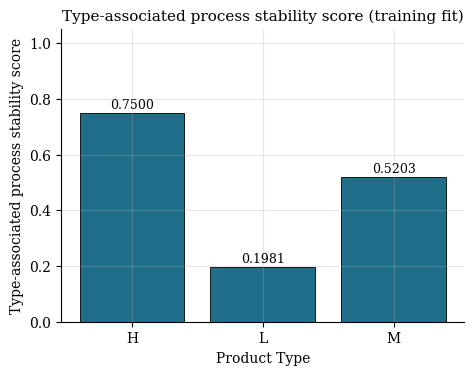

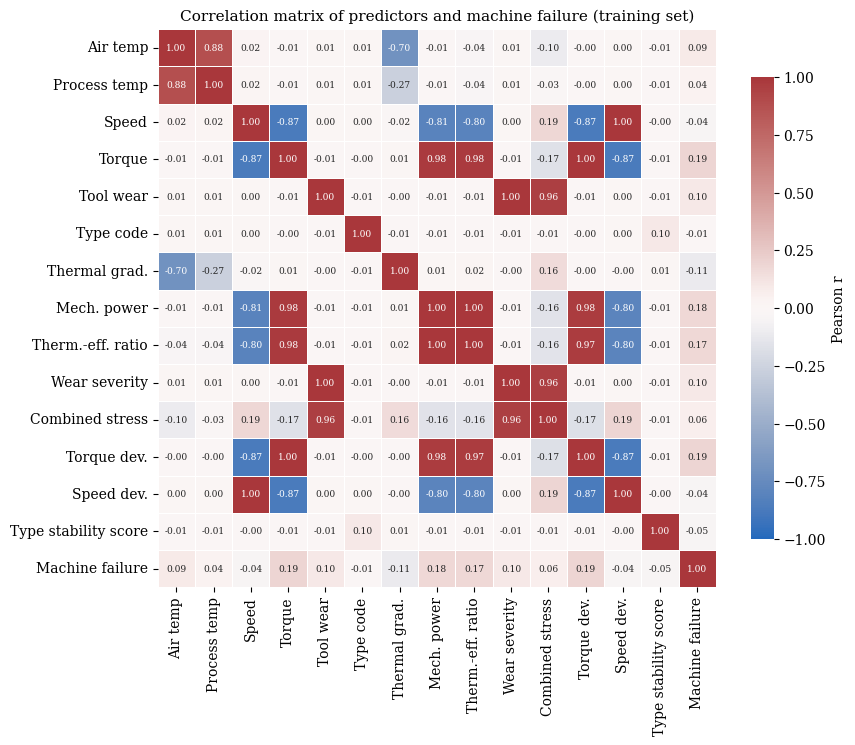

In [10]:
# Figure 4 - Type-associated process stability score (fitted on training data)
fig, ax = plt.subplots(figsize=(5.2, 3.8))
ax.bar(score_tbl["Type"], score_tbl[SCORE_COL], color=PAL[1], edgecolor="black", linewidth=0.6)
for i, v in enumerate(score_tbl[SCORE_COL]):
    ax.text(i, v + 0.015, f"{v:.4f}", ha="center", fontsize=9)
ax.set_xlabel("Product Type"); ax.set_ylabel("Type-associated process stability score")
ax.set_title("Type-associated process stability score (training fit)"); ax.set_ylim(0, 1.05)
save_fig(fig, "fig04_type_associated_stability_score")

# Figure 2 - correlation heatmap computed from the training dataframe (features + target; descriptive)
short = {"Air temperature [K]": "Air temp", "Process temperature [K]": "Process temp", "Rotational speed [rpm]": "Speed", "Torque [Nm]": "Torque",
         "Tool wear [min]": "Tool wear", TYPE_COL: "Type code", "thermal_gradient": "Thermal grad.", "mechanical_power": "Mech. power",
         "thermal_efficiency": "Therm.-eff. ratio", "tool_wear_severity": "Wear severity", "combined_stress_index": "Combined stress",
         "torque_deviation": "Torque dev.", "speed_deviation": "Speed dev.", SCORE_COL: "Type stability score", TARGET: "Machine failure"}
corr = pd.concat([Ftr[ALL14], ytr.rename(TARGET)], axis=1).corr()
corr = corr.rename(index=short, columns=short)
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", annot_kws={"size": 6.5}, cmap="vlag", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.4, cbar_kws={"shrink": 0.8, "label": "Pearson r"}, ax=ax)
ax.set_title("Correlation matrix of predictors and machine failure (training set)"); ax.grid(False)
save_fig(fig, "fig02_correlation_heatmap")

# 5. Feature-set dependency comparison

Five feature sets are compared with the **same** framework: repeated stratified 5-fold CV (3 repeats) **on the training set only**, with the whole pipeline
(feature construction, score mapping, SMOTE, scaling, XGBoost) refitted inside each training fold. A sixth set (raw5 + one-hot Type) is added as a diagnostic to separate
"information about Type" from "arbitrary ordinal coding of Type". SD = population SD across folds (ddof = 0).

In [11]:
ONEHOT = [f"Type_is_{n}" for n in TYPE_NAME_MAP.values()]
FEATURE_SETS = {"raw5": RAW5,
                "raw5+Type": RAW5 + [TYPE_COL],
                "raw5+score": RAW5 + [SCORE_COL],
                "raw5+Type+score": RAW5 + [TYPE_COL, SCORE_COL],
                "all14 (all engineered)": ALL14,
                "raw5+Type one-hot (diagnostic)": RAW5 + ONEHOT}
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
dep_folds, rows = {}, []
t0 = time.time()
for name, cols in FEATURE_SETS.items():
    f1s, aps, aucs = [], [], []
    for a, b in rcv.split(Xtr, ytr):
        m = make_pipe(make_xgb(), cols).fit(Xtr.iloc[a], ytr.iloc[a])
        q = m.predict_proba(Xtr.iloc[b])[:, 1]
        f1s.append(f1_score(ytr.iloc[b], q > DEFAULT_THRESHOLD)); aps.append(average_precision_score(ytr.iloc[b], q)); aucs.append(roc_auc_score(ytr.iloc[b], q))
    dep_folds[name] = {"F1": np.array(f1s), "PR_AUC": np.array(aps), "ROC_AUC": np.array(aucs)}
    rows.append({"Feature set": name, "n_features": len(cols),
                 "F1_mean": np.mean(f1s), "F1_SD": np.std(f1s, ddof=SD_DDOF),
                 "PR_AUC_mean": np.mean(aps), "PR_AUC_SD": np.std(aps, ddof=SD_DDOF),
                 "ROC_AUC_mean": np.mean(aucs), "ROC_AUC_SD": np.std(aucs, ddof=SD_DDOF)})
dep_df = pd.DataFrame(rows)
print(f"Done in {time.time() - t0:.0f}s | {rcv.get_n_splits()} train/validation fits per feature set")
display(dep_df.round(4))

Done in 14s | 15 train/validation fits per feature set


,Feature set,n_features,F1_mean,F1_SD,PR_AUC_mean,PR_AUC_SD,ROC_AUC_mean,ROC_AUC_SD
0,raw5,5,0.6068,0.0269,0.7121,0.0533,0.9665,0.0095
1,raw5+Type,6,0.6543,0.0223,0.7530,0.0311,0.9647,0.0105
2,raw5+score,6,0.6496,0.0265,0.7566,0.0349,0.9644,0.0099
3,raw5+Type+score,7,0.6565,0.0246,0.7529,0.0351,0.9647,0.0109
4,all14 (all engineered),14,0.7295,0.0356,0.8245,0.0328,0.9661,0.0109
5,raw5+Type one-hot (diagnostic),8,0.6569,0.0325,0.7547,0.0346,0.9654,0.0103


In [12]:
g = dep_df.set_index("Feature set")
def d(a, b, m="F1_mean"): return g.loc[a, m] - g.loc[b, m]
sd_ref = g.loc["raw5+Type", "F1_SD"]
print("Differences in mean F1 (compare with the fold-to-fold SD, about %.3f):" % sd_ref)
print(f"  raw5+Type            - raw5               = {d('raw5+Type', 'raw5'):+.4f}")
print(f"  raw5+score           - raw5               = {d('raw5+score', 'raw5'):+.4f}")
print(f"  raw5+Type+score      - raw5+score         = {d('raw5+Type+score', 'raw5+score'):+.4f}   (does Type add anything once the score is present?)")
print(f"  raw5+Type+score      - raw5+Type          = {d('raw5+Type+score', 'raw5+Type'):+.4f}   (does the score add anything once Type is present?)")
print(f"  raw5+score           - raw5+Type one-hot  = {d('raw5+score', 'raw5+Type one-hot (diagnostic)'):+.4f}   (ordinal-code effect, not new information)")
print(f"  all14                - raw5+Type+score    = {d('all14 (all engineered)', 'raw5+Type+score'):+.4f}   (contribution of the engineered process features)")
print()
print("Interpretation: the score is a one-to-one relabelling of Type (see Section 4), so it cannot contain information beyond Type. Any F1 difference between "
      "raw5+Type and raw5+score therefore reflects how a tree model can split on a 3-valued numeric code (the ordering of the code), not additional "
      "predictive content. Differences smaller than about one fold-SD should not be read as real effects; the one-hot diagnostic shows what 'Type information' alone yields.")

Differences in mean F1 (compare with the fold-to-fold SD, about 0.022):
  raw5+Type            - raw5               = +0.0476
  raw5+score           - raw5               = +0.0429
  raw5+Type+score      - raw5+score         = +0.0069   (does Type add anything once the score is present?)
  raw5+Type+score      - raw5+Type          = +0.0022   (does the score add anything once Type is present?)
  raw5+score           - raw5+Type one-hot  = -0.0073   (ordinal-code effect, not new information)
  all14                - raw5+Type+score    = +0.0730   (contribution of the engineered process features)

Interpretation: the score is a one-to-one relabelling of Type (see Section 4), so it cannot contain information beyond Type. Any F1 difference between raw5+Type and raw5+score therefore reflects how a tree model can split on a 3-valued numeric code (the ordering of the code), not additional predictive content. Differences smaller than about one fold-SD should not be read as real effects; the one

# 6. Model benchmarking (one split, one preprocessing framework)

All seven models use the same pipeline: feature construction (fitted on the training set) → SMOTE (training only) → `StandardScaler` → classifier, evaluated once on the held-out test set
at the default 0.5 decision rule (`predict` for the SVM). McNemar's test compares each model with XGBoost on the same test rows.
Exact numbers can vary slightly with library versions; versions are recorded at the end of the notebook.

In [13]:
Fte = fe_main.transform(Xte)           # FIRST use of the test features: final evaluation from here on

def make_models():
    return {"Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
            "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
            "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
            "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
            "XGBoost": make_xgb(),
            "SVM": SVC(probability=True, random_state=RANDOM_STATE),
            "Neural Network (MLP)": MLPClassifier(hidden_layer_sizes=(64, 32), random_state=RANDOM_STATE, max_iter=500)}
MAIN_MODEL = "XGBoost"

fitted, probas, preds, bench_rows = {}, {}, {}, []
for name, clf in make_models().items():
    t0 = time.time()
    model = make_pipe(clf).fit(Xtr, ytr)
    fit_s = time.time() - t0
    p = model.predict_proba(Xte)[:, 1]
    yhat = model.predict(Xte) if name == "SVM" else (p > DEFAULT_THRESHOLD).astype(int)
    fitted[name], probas[name], preds[name] = model, p, yhat
    r = evaluate(yte, yhat, p); r.update({"Model": name, "Fit_time_s": fit_s}); bench_rows.append(r)
    print(f"{name:22s} F1={r['F1']:.4f} Recall={r['Recall']:.4f} Precision={r['Precision']:.4f} PR-AUC={r['PR_AUC']:.4f} ({fit_s:.1f}s)")

def mcnemar_p(y, a, b):
    ca, cb = (a == y), (b == y)
    n01, n10 = int((ca & ~cb).sum()), int((~ca & cb).sum())
    if n01 + n10 == 0: return 1.0
    return float(1 - chi2_dist.cdf((abs(n01 - n10) - 1) ** 2 / (n01 + n10), 1))

bench_df = pd.DataFrame(bench_rows)
bench_df["McNemar_p_vs_XGBoost"] = [np.nan if m == MAIN_MODEL else mcnemar_p(yte.values, preds[m], preds[MAIN_MODEL]) for m in bench_df["Model"]]
bench_df = bench_df[["Model"] + METRICS + ["TN", "FP", "FN", "TP", "Fit_time_s", "McNemar_p_vs_XGBoost"]]
print("\nHeld-out test benchmark:")
display(bench_df.round(4))
joblib.dump(fitted[MAIN_MODEL], OUT_DIR / "xgboost_pipeline.joblib")

Logistic Regression    F1=0.3093 Recall=0.8529 Precision=0.1889 PR-AUC=0.4195 (0.1s)
Decision Tree          F1=0.5397 Recall=0.7500 Precision=0.4215 PR-AUC=0.3246 (0.3s)
Random Forest          F1=0.5641 Recall=0.6471 Precision=0.5000 PR-AUC=0.6651 (3.8s)
Gradient Boosting      F1=0.5288 Recall=0.8088 Precision=0.3929 PR-AUC=0.6956 (7.9s)
XGBoost                F1=0.7114 Recall=0.7794 Precision=0.6543 PR-AUC=0.7893 (0.2s)
SVM                    F1=0.4508 Recall=0.8088 Precision=0.3125 PR-AUC=0.5266 (18.7s)
Neural Network (MLP)   F1=0.5581 Recall=0.7059 Precision=0.4615 PR-AUC=0.6348 (8.0s)

Held-out test benchmark:


,Model,F1,Recall,Precision,MCC,ROC_AUC,PR_AUC,TN,FP,FN,TP,Fit_time_s,McNemar_p_vs_XGBoost
0,Logistic Regression,0.3093,0.8529,0.1889,0.3640,0.9371,0.4195,1683,249,10,58,0.1200,0.0000
1,Decision Tree,0.5397,0.7500,0.4215,0.5426,0.8569,0.3246,1862,70,17,51,0.2673,0.0000
2,Random Forest,0.5641,0.6471,0.5000,0.5516,0.9655,0.6651,1888,44,24,44,3.8267,0.0001
3,Gradient Boosting,0.5288,0.8088,0.3929,0.5433,0.9609,0.6956,1847,85,13,55,7.9409,0.0000
4,XGBoost,0.7114,0.7794,0.6543,0.7032,0.9652,0.7893,1904,28,15,53,0.1807,NaN
5,SVM,0.4508,0.8088,0.3125,0.4774,0.9611,0.5266,1811,121,13,55,18.6537,0.0000
6,Neural Network (MLP),0.5581,0.7059,0.4615,0.5525,0.9591,0.6348,1876,56,20,48,8.0452,0.0000


['outputs\\xgboost_pipeline.joblib']

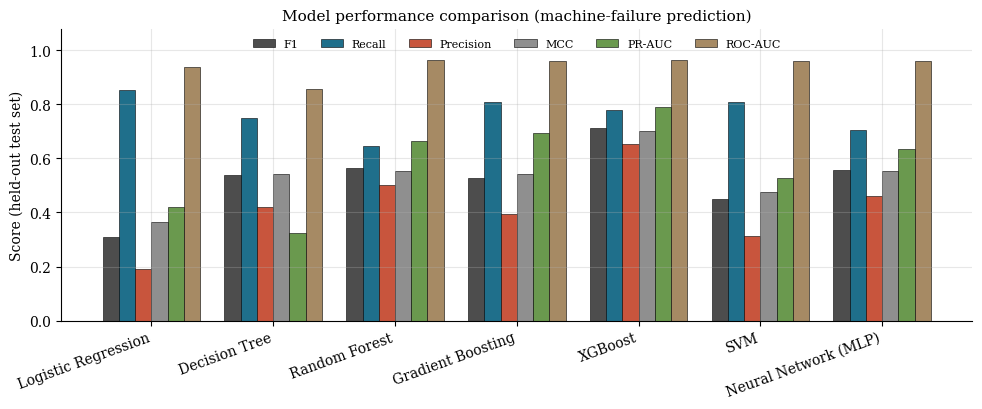

In [14]:
# Figure 5 - model performance comparison (computed from bench_df)
fig, ax = plt.subplots(figsize=(10, 4.2))
mets = ["F1", "Recall", "Precision", "MCC", "PR_AUC", "ROC_AUC"]
w = 0.8 / len(mets); xx = np.arange(len(bench_df))
for k, m in enumerate(mets):
    ax.bar(xx + k * w - 0.4 + w / 2, bench_df[m], w, label=m.replace("_", "-"), color=PAL[k % len(PAL)], edgecolor="black", linewidth=0.4)
ax.set_xticks(xx); ax.set_xticklabels(bench_df["Model"], rotation=20, ha="right")
ax.set_ylabel("Score (held-out test set)"); ax.set_ylim(0, 1.08)
ax.set_title("Model performance comparison (machine-failure prediction)"); ax.legend(ncol=6, frameon=False, fontsize=8, loc="upper center")
fig.tight_layout(); save_fig(fig, "fig05_model_performance_comparison")

## 6.1 Final XGBoost: confusion matrix and metric verification

Precision and recall are recomputed from the confusion-matrix cells and must match the reported metrics; otherwise the notebook stops with an error.

In [15]:
pr_xgb, p_def = probas[MAIN_MODEL], preds[MAIN_MODEL]
xgb_def = evaluate(yte, p_def, pr_xgb)
TN, FP, FN, TP = xgb_def["TN"], xgb_def["FP"], xgb_def["FN"], xgb_def["TP"]
cm_def = np.array([[TN, FP], [FN, TP]])

print("XGBoost on the held-out test set (default threshold 0.5)")
for m in METRICS: print(f"  {m:10s} = {xgb_def[m]:.7f}")
print("  confusion matrix [[TN, FP], [FN, TP]] =", cm_def.tolist())

# ---- automatic consistency checks (raise on mismatch) ----
assert TN + FP + FN + TP == len(yte), "confusion matrix does not sum to the test-set size"
assert TP + FN == int(yte.sum()) and TN + FP == int((yte == 0).sum())
assert np.isclose(precision_score(yte, p_def), TP / (TP + FP)) and np.isclose(xgb_def["Precision"], TP / (TP + FP))
assert np.isclose(recall_score(yte, p_def), TP / (TP + FN)) and np.isclose(xgb_def["Recall"], TP / (TP + FN))
assert np.isclose(f1_score(yte, p_def), 2 * TP / (2 * TP + FP + FN))
print("Consistency checks passed: precision == TP/(TP+FP), recall == TP/(TP+FN), F1 == 2TP/(2TP+FP+FN).")

XGBoost on the held-out test set (default threshold 0.5)
  F1         = 0.7114094
  Recall     = 0.7794118
  Precision  = 0.6543210
  MCC        = 0.7032237
  ROC_AUC    = 0.9652067
  PR_AUC     = 0.7892951
  confusion matrix [[TN, FP], [FN, TP]] = [[1904, 28], [15, 53]]
Consistency checks passed: precision == TP/(TP+FP), recall == TP/(TP+FN), F1 == 2TP/(2TP+FP+FN).


In [16]:
# ---- Bootstrap 95% confidence intervals (percentile) for final XGBoost test metrics, default threshold ----
def bootstrap_ci(y_true, y_pred, y_score, n_boot=N_BOOT, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true, y_pred, y_score = np.asarray(y_true), np.asarray(y_pred), np.asarray(y_score)
    vals = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y_true), len(y_true))
        if y_true[i].sum() == 0 or y_true[i].sum() == len(i):
            continue
        vals.append([f1_score(y_true[i], y_pred[i], zero_division=0), recall_score(y_true[i], y_pred[i], zero_division=0),
                     precision_score(y_true[i], y_pred[i], zero_division=0),
                     average_precision_score(y_true[i], y_score[i]), roc_auc_score(y_true[i], y_score[i])])
    vals = np.array(vals)
    lo, hi = np.percentile(vals, [2.5, 97.5], axis=0)
    return vals, lo, hi

boot_vals, ci_lo, ci_hi = bootstrap_ci(yte, p_def, pr_xgb)
BOOT_METRICS = ["F1", "Recall", "Precision", "PR_AUC", "ROC_AUC"]
boot_df = pd.DataFrame({"Metric": BOOT_METRICS, "Point_estimate": [xgb_def[m] for m in BOOT_METRICS],
                        "CI95_low": ci_lo, "CI95_high": ci_hi, "Bootstrap_mean": boot_vals.mean(axis=0)})
print(f"Bootstrap resamples used: {len(boot_vals)} of {N_BOOT} requested (seed = {RANDOM_STATE})")
display(boot_df.round(4))

Bootstrap resamples used: 2000 of 2000 requested (seed = 42)


,Metric,Point_estimate,CI95_low,CI95_high,Bootstrap_mean
0,F1,0.7114,0.6197,0.7901,0.7094
1,Recall,0.7794,0.6710,0.8750,0.7788
2,Precision,0.6543,0.5467,0.7561,0.6538
3,PR_AUC,0.7893,0.6875,0.8775,0.7902
4,ROC_AUC,0.9652,0.9401,0.9845,0.9650


## 6.2 ROC and precision–recall analysis

Because machine failures are rare, **PR-AUC is the primary threshold-free metric**; its no-skill baseline equals the failure prevalence (not 0.5 as for ROC-AUC).

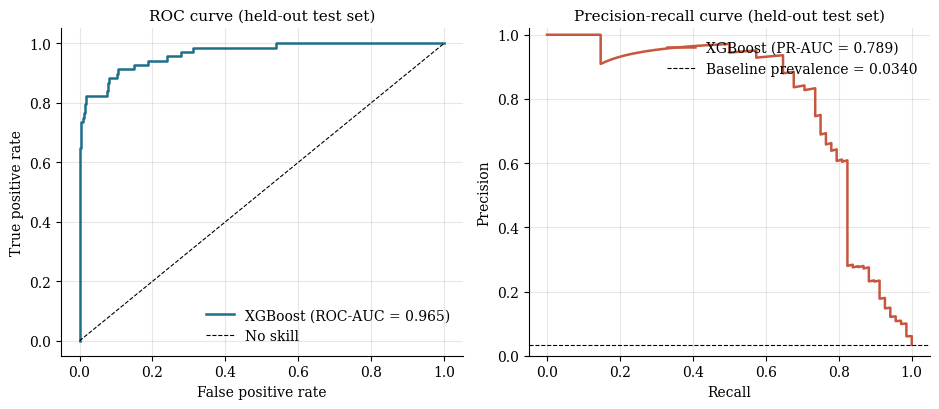

ROC-AUC = 0.9652 | PR-AUC = 0.7893 (no-skill PR baseline = 0.0340; PR-AUC is 23.2x the baseline)


In [17]:
fpr, tpr, _ = roc_curve(yte, pr_xgb)
prec_c, rec_c, _ = precision_recall_curve(yte, pr_xgb)
prevalence_test = float(yte.mean())

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))
ax = axes[0]
ax.plot(fpr, tpr, color=PAL[1], lw=1.8, label=f"XGBoost (ROC-AUC = {xgb_def['ROC_AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="No skill")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_title("ROC curve (held-out test set)"); ax.legend(frameon=False, loc="lower right")
ax = axes[1]
ax.plot(rec_c, prec_c, color=PAL[2], lw=1.8, label=f"XGBoost (PR-AUC = {xgb_def['PR_AUC']:.3f})")
ax.axhline(prevalence_test, color="black", ls="--", lw=0.8, label=f"Baseline prevalence = {prevalence_test:.4f}")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_ylim(0, 1.02); ax.set_title("Precision-recall curve (held-out test set)"); ax.legend(frameon=False, loc="upper right")
fig.tight_layout(); save_fig(fig, "fig07_08_roc_and_precision_recall_curves")
print(f"ROC-AUC = {xgb_def['ROC_AUC']:.4f} | PR-AUC = {xgb_def['PR_AUC']:.4f} (no-skill PR baseline = {prevalence_test:.4f}; PR-AUC is {xgb_def['PR_AUC'] / prevalence_test:.1f}x the baseline)")

# 7. Five-fold stratified cross-validation (SMOTE inside each fold)

Folds are drawn on the **training set only**. The full pipeline — including feature construction, SMOTE, scaler and classifier — is refitted in every training fold, so no validation-fold information is used in fitting.
Random Forest is reported because it is the model used for the fold table in the manuscript; XGBoost (the final model) is reported alongside.

In [18]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def run_cv(factory):
    rows = []
    for k, (a, b) in enumerate(cv5.split(Xtr, ytr), 1):
        m = make_pipe(factory()).fit(Xtr.iloc[a], ytr.iloc[a])
        q = m.predict_proba(Xtr.iloc[b])[:, 1]
        r = evaluate(ytr.iloc[b], (q > DEFAULT_THRESHOLD).astype(int), q)
        r.update({"Fold": k, "n_failures": int(ytr.iloc[b].sum()), "n_validation": len(b)}); rows.append(r)
    return pd.DataFrame(rows).set_index("Fold")

cv_models = {"Random Forest": lambda: RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE), "XGBoost": make_xgb}
cv_raw = {name: run_cv(f) for name, f in cv_models.items()}

CV_COLS = METRICS + ["n_failures"]
def cv_table(df, model_name):
    t = df[CV_COLS].copy().astype(float)
    t.index = [f"Fold {i}" for i in t.index]
    mean_, sd_ = t.mean(), t.std(ddof=SD_DDOF)
    t.loc["Mean"] = mean_; t.loc["SD (ddof=0)"] = sd_
    t["n_failures"] = t["n_failures"].astype(float)
    ms = {c: (f"{mean_[c]:.1f} ± {sd_[c]:.1f}" if c == "n_failures" else f"{mean_[c]:.4f} ± {sd_[c]:.4f}") for c in CV_COLS}
    t = t.astype(object); t.loc["Mean ± SD"] = pd.Series(ms)
    t.insert(0, "Model", model_name); t.index.name = "Row"
    return t

cv_tables = {name: cv_table(df, name) for name, df in cv_raw.items()}
for name, t in cv_tables.items():
    print(f"\n{name} — 5-fold stratified CV on the training set (SMOTE inside each fold)")
    display(t.drop(columns="Model"))
table4 = pd.concat(cv_tables.values()).reset_index()


Random Forest — 5-fold stratified CV on the training set (SMOTE inside each fold)


,F1,Recall,Precision,MCC,ROC_AUC,PR_AUC,n_failures
Row,,,,,,,
Fold 1,0.676923,0.814815,0.578947,0.674196,0.979834,0.79647,54.0
Fold 2,0.598425,0.703704,0.520548,0.589398,0.9723,0.671455,54.0
Fold 3,0.651515,0.796296,0.551282,0.648777,0.952452,0.770425,54.0
Fold 4,0.634146,0.722222,0.565217,0.624787,0.97257,0.722885,54.0
Fold 5,0.681818,0.818182,0.584416,0.678835,0.957829,0.779249,55.0
Mean,0.648566,0.771044,0.560082,0.643199,0.966997,0.748097,54.2
SD (ddof=0),0.030465,0.048361,0.022868,0.033152,0.010194,0.045428,0.4
Mean ± SD,0.6486 ± 0.0305,0.7710 ± 0.0484,0.5601 ± 0.0229,0.6432 ± 0.0332,0.9670 ± 0.0102,0.7481 ± 0.0454,54.2 ± 0.4



XGBoost — 5-fold stratified CV on the training set (SMOTE inside each fold)


,F1,Recall,Precision,MCC,ROC_AUC,PR_AUC,n_failures
Row,,,,,,,
Fold 1,0.682927,0.777778,0.608696,0.675899,0.973037,0.825802,54.0
Fold 2,0.649573,0.703704,0.603175,0.638393,0.959897,0.746059,54.0
Fold 3,0.732143,0.759259,0.706897,0.722936,0.95011,0.802133,54.0
Fold 4,0.743363,0.777778,0.711864,0.734761,0.967287,0.812793,54.0
Fold 5,0.758065,0.854545,0.681159,0.753652,0.969509,0.863241,55.0
Mean,0.713214,0.774613,0.662358,0.705128,0.963968,0.810006,54.2
SD (ddof=0),0.040611,0.048318,0.047266,0.04209,0.008156,0.038059,0.4
Mean ± SD,0.7132 ± 0.0406,0.7746 ± 0.0483,0.6624 ± 0.0473,0.7051 ± 0.0421,0.9640 ± 0.0082,0.8100 ± 0.0381,54.2 ± 0.4


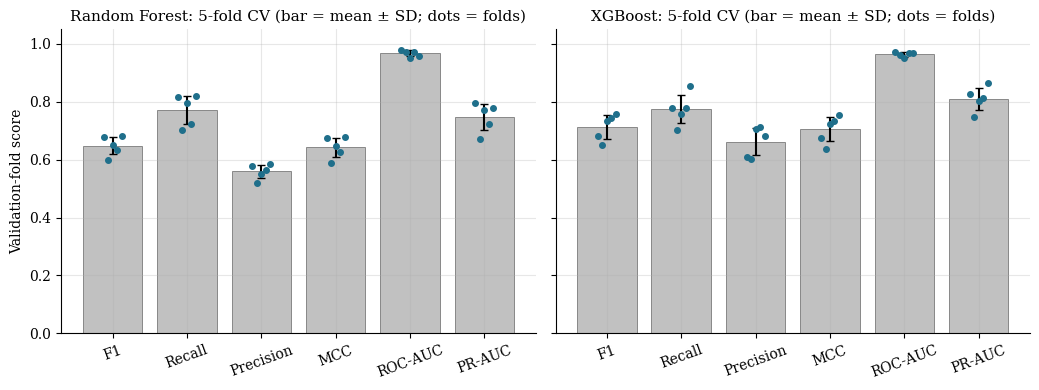

In [19]:
# Figure 9 - cross-validation performance (fold points, mean and SD)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4), sharey=True)
for ax, (name, df) in zip(axes, cv_raw.items()):
    for j, m in enumerate(METRICS):
        v = df[m].values
        ax.bar(j, v.mean(), yerr=v.std(ddof=SD_DDOF), capsize=3, color=PAL[3], alpha=0.55, edgecolor="black", linewidth=0.5)
        ax.scatter(np.full(len(v), j) + np.linspace(-0.12, 0.12, len(v)), v, color=PAL[1], s=16, zorder=3)
    ax.set_xticks(range(len(METRICS))); ax.set_xticklabels([m.replace("_", "-") for m in METRICS], rotation=20)
    ax.set_title(f"{name}: 5-fold CV (bar = mean ± SD; dots = folds)"); ax.set_ylim(0, 1.05)
axes[0].set_ylabel("Validation-fold score")
fig.tight_layout(); save_fig(fig, "fig09_cross_validation_performance")

# 8. Threshold selection without the test set

The F1-optimal threshold is chosen **only from out-of-fold (OOF) probabilities on the training set**, then frozen and applied once to the test set.
A threshold tuned on the test set is computed purely as a labelled, optimistic diagnostic.

In [20]:
oof = cross_val_predict(make_pipe(make_xgb()), Xtr, ytr, cv=cv5, method="predict_proba")[:, 1]
thr_oof, f1_oof = best_f1_threshold(ytr, oof)                       # uses training labels/OOF scores only
FINAL_THRESHOLD = thr_oof                                           # frozen
print(f"Selected OOF threshold (training only): {thr_oof:.4f} | OOF F1 at that threshold: {f1_oof:.4f}")

oof_eval = evaluate(ytr, (oof >= thr_oof).astype(int), oof)
p_oofthr = (pr_xgb >= FINAL_THRESHOLD).astype(int)                  # applied once to the test set
xgb_oofthr = evaluate(yte, p_oofthr, pr_xgb)

TEST_OPT_LABEL = "TEST-OPTIMIZED THRESHOLD — OPTIMISTIC, NOT VALID FOR UNBIASED PERFORMANCE REPORTING"
thr_test_opt, f1_test_opt = best_f1_threshold(yte, pr_xgb)          # diagnostic only
xgb_testopt = evaluate(yte, (pr_xgb >= thr_test_opt).astype(int), pr_xgb)

def cm_of(r): return [[r["TN"], r["FP"]], [r["FN"], r["TP"]]]
rows9 = [("Training OOF (selection set)", thr_oof, "training OOF predictions", oof_eval),
         ("Test @ default 0.5", DEFAULT_THRESHOLD, "fixed default", xgb_def),
         ("Test @ OOF-selected threshold (final)", FINAL_THRESHOLD, "training OOF predictions", xgb_oofthr),
         (TEST_OPT_LABEL, thr_test_opt, "TEST SET (diagnostic only)", xgb_testopt)]
table9 = pd.DataFrame([{"Setting": s, "Threshold": t, "Threshold_source": src, **{m: r[m] for m in ["F1", "Recall", "Precision", "MCC"]},
                        "TN": r["TN"], "FP": r["FP"], "FN": r["FN"], "TP": r["TP"]} for s, t, src, r in rows9])
display(table9.round(4))

print("\nConfusion matrices [[TN, FP], [FN, TP]]")
print("  default 0.5 threshold       :", cm_of(xgb_def))
print(f"  OOF-selected ({thr_oof:.3f})       :", cm_of(xgb_oofthr))
print(f"\n{TEST_OPT_LABEL}\n  threshold = {thr_test_opt:.3f}, F1 = {f1_test_opt:.4f}  -> NOT used for any reported final result.")

Selected OOF threshold (training only): 0.8672 | OOF F1 at that threshold: 0.7708


,Setting,Threshold,Threshold_source,F1,Recall,Precision,MCC,TN,FP,FN,TP
0,Training OOF (selection set),0.8672,training OOF predictions,0.7708,0.7011,0.8559,0.7676,7697,32,81,190
1,Test @ default 0.5,0.5000,fixed default,0.7114,0.7794,0.6543,0.7032,1904,28,15,53
2,Test @ OOF-selected threshold (final),0.8672,training OOF predictions,0.7581,0.6912,0.8393,0.7542,1923,9,21,47
3,"TEST-OPTIMIZED THRESHOLD — OPTIMISTIC, NOT VAL...",0.8528,TEST SET (diagnostic only),0.7812,0.7353,0.8333,0.7757,1922,10,18,50



Confusion matrices [[TN, FP], [FN, TP]]
  default 0.5 threshold       : [[1904, 28], [15, 53]]
  OOF-selected (0.867)       : [[1923, 9], [21, 47]]

TEST-OPTIMIZED THRESHOLD — OPTIMISTIC, NOT VALID FOR UNBIASED PERFORMANCE REPORTING
  threshold = 0.853, F1 = 0.7812  -> NOT used for any reported final result.


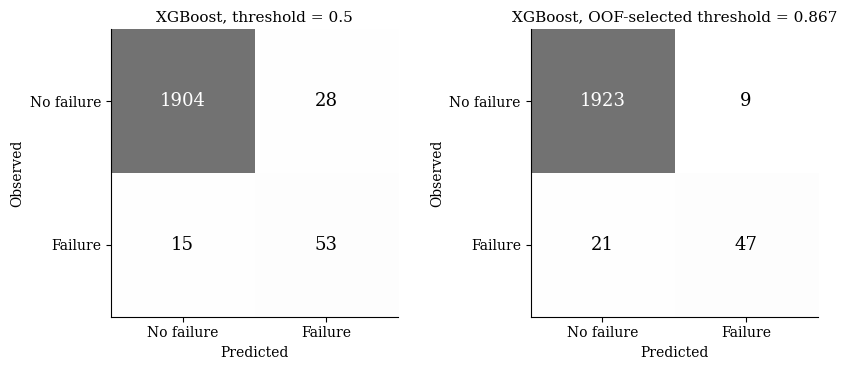

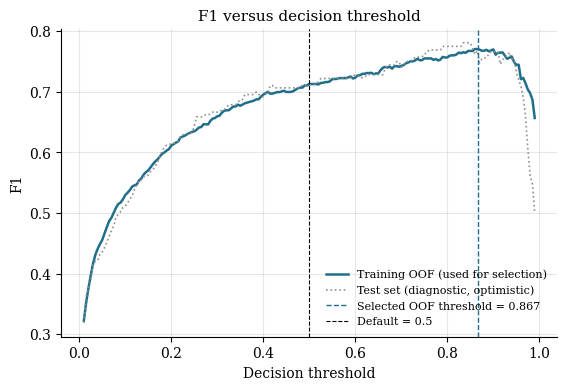

In [21]:
# Figure 6 - confusion matrices of the final XGBoost at both thresholds
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.8))
plot_cm(axes[0], cm_of(xgb_def), f"XGBoost, threshold = {DEFAULT_THRESHOLD}")
plot_cm(axes[1], cm_of(xgb_oofthr), f"XGBoost, OOF-selected threshold = {FINAL_THRESHOLD:.3f}")
fig.tight_layout(); save_fig(fig, "fig06_confusion_matrix_xgboost")

# Figure 10 - threshold vs F1 (OOF curve used for selection; test curve shown only as an optimistic diagnostic)
grid = np.linspace(0.01, 0.99, 197)
f1_oof_curve = [f1_score(ytr, oof >= t, zero_division=0) for t in grid]
f1_test_curve = [f1_score(yte, pr_xgb >= t, zero_division=0) for t in grid]
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.plot(grid, f1_oof_curve, color=PAL[1], lw=1.8, label="Training OOF (used for selection)")
ax.plot(grid, f1_test_curve, color=PAL[3], lw=1.2, ls=":", label="Test set (diagnostic, optimistic)")
ax.axvline(FINAL_THRESHOLD, color=PAL[1], ls="--", lw=1, label=f"Selected OOF threshold = {FINAL_THRESHOLD:.3f}")
ax.axvline(DEFAULT_THRESHOLD, color="black", ls="--", lw=0.8, label=f"Default = {DEFAULT_THRESHOLD}")
ax.set_xlabel("Decision threshold"); ax.set_ylabel("F1"); ax.set_title("F1 versus decision threshold"); ax.legend(frameon=False, fontsize=8)
save_fig(fig, "fig10_threshold_vs_f1")

# 9. Feature importance and ablation from actual model outputs

* **Permutation importance** (held-out test set, final XGBoost): each feature of the model input is shuffled (30 repeats, fixed seed); importance = drop in PR-AUC and in F1 (default threshold).
  Note: permuting `type_process_stability_score` independently of `Type_encoded` breaks their one-to-one link, so the two Type-derived features partly share importance.
* **Ablation**: for each of the 14 features, the **entire pipeline is retrained without it** (same training procedure and seed) and evaluated on the same test set.
  `F1 drop = F1(full model) − F1(model without feature)`. **A negative drop means performance *improved* after removing the feature.**
  Differences of about 0.01 are within the sampling uncertainty of a 68-failure test set (see the bootstrap intervals) and should not be over-interpreted.

In [22]:
model_xgb = fitted[MAIN_MODEL]
Fte_all = Fte[ALL14]
base_p = proba_from_features(model_xgb, Fte_all)
assert np.allclose(base_p, pr_xgb), "feature-level scoring does not reproduce the pipeline's probabilities"
base_ap, base_f1 = average_precision_score(yte, base_p), f1_score(yte, base_p > DEFAULT_THRESHOLD)

N_PERM = 30
rng_perm = np.random.default_rng(RANDOM_STATE)
perm_rows = []
for c in ALL14:
    d_ap, d_f1 = [], []
    for _ in range(N_PERM):
        Fp = Fte_all.copy(); Fp[c] = rng_perm.permutation(Fp[c].values)
        q = proba_from_features(model_xgb, Fp)
        d_ap.append(base_ap - average_precision_score(yte, q)); d_f1.append(base_f1 - f1_score(yte, q > DEFAULT_THRESHOLD))
    perm_rows.append({"Feature": c, "PR_AUC_drop_mean": np.mean(d_ap), "PR_AUC_drop_SD": np.std(d_ap),
                      "F1_drop_mean": np.mean(d_f1), "F1_drop_SD": np.std(d_f1)})
perm_df = pd.DataFrame(perm_rows).sort_values("PR_AUC_drop_mean", ascending=False).reset_index(drop=True)
display(perm_df.round(4))

,Feature,PR_AUC_drop_mean,PR_AUC_drop_SD,F1_drop_mean,F1_drop_SD
0,Rotational speed [rpm],0.3492,0.0401,0.2688,0.0385
1,thermal_gradient,0.3336,0.0256,0.2594,0.0210
2,mechanical_power,0.1842,0.0139,0.1604,0.0242
3,Tool wear [min],0.1211,0.0179,0.0821,0.0165
4,Torque [Nm],0.0812,0.0193,0.0421,0.0176
5,combined_stress_index,0.0573,0.0183,0.0453,0.0214
6,thermal_efficiency,0.0354,0.0091,0.0295,0.0154
7,type_process_stability_score,0.0274,0.0202,0.0800,0.0163
8,Air temperature [K],0.0233,0.0123,-0.0038,0.0179
9,speed_deviation,0.0163,0.0087,-0.0118,0.0184


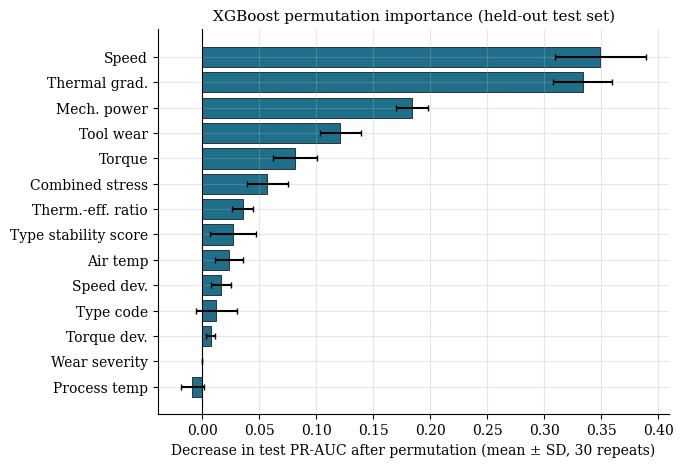

SHAP figure skipped (optional dependency / compatibility): ModuleNotFoundError No module named 'shap'


In [23]:
# Figure 3 - XGBoost permutation importance (held-out test set)
pd_ = perm_df.sort_values("PR_AUC_drop_mean")
fig, ax = plt.subplots(figsize=(6.6, 5))
ax.barh(pd_["Feature"].map(short), pd_["PR_AUC_drop_mean"], xerr=pd_["PR_AUC_drop_SD"], color=PAL[1], edgecolor="black", linewidth=0.5, capsize=2)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Decrease in test PR-AUC after permutation (mean ± SD, 30 repeats)")
ax.set_title("XGBoost permutation importance (held-out test set)")
save_fig(fig, "fig03_xgboost_permutation_importance")

# Optional: SHAP summary (explanation only; not used for any selection)
try:
    import shap
    A_te = model_xgb.named_steps["sc"].transform(model_xgb.named_steps["sel"].transform(Fte_all))
    sv = shap.TreeExplainer(model_xgb.named_steps["clf"]).shap_values(A_te)
    sv = sv[1] if isinstance(sv, list) else sv
    shap_imp = pd.Series(np.abs(sv).mean(axis=0), index=ALL14).sort_values()
    fig, ax = plt.subplots(figsize=(6.6, 5))
    ax.barh(shap_imp.index.map(short), shap_imp.values, color=PAL[3], edgecolor="black", linewidth=0.5)
    ax.set_xlabel("Mean |SHAP value| (test set)"); ax.set_title("XGBoost SHAP importance (held-out test set)")
    save_fig(fig, "fig03b_xgboost_shap_importance")
except Exception as e:
    print("SHAP figure skipped (optional dependency / compatibility):", type(e).__name__, str(e)[:100])

In [24]:
# Ablation: retrain the ENTIRE pipeline without each feature; same training data, same seed, same test set
abl_rows = []
t0 = time.time()
for feat in ALL14:
    cols = [c for c in ALL14 if c != feat]
    m = make_pipe(make_xgb(), cols).fit(Xtr, ytr)
    q = m.predict_proba(Xte)[:, 1]
    f1_wo = f1_score(yte, q > DEFAULT_THRESHOLD)
    abl_rows.append({"Feature": feat, "F1_without_feature": f1_wo, "F1_drop": xgb_def["F1"] - f1_wo,
                     "PR_AUC_without_feature": average_precision_score(yte, q),
                     "PR_AUC_drop": xgb_def["PR_AUC"] - average_precision_score(yte, q)})
abl_df = pd.DataFrame(abl_rows).sort_values("F1_drop", ascending=False).reset_index(drop=True)
abl_df.insert(1, "Baseline_F1_full_model", xgb_def["F1"])
print(f"Baseline (all 14 features) test F1 = {xgb_def['F1']:.4f}  | ablation done in {time.time() - t0:.0f}s")
print("F1 drop > 0: performance worsened without the feature | F1 drop < 0: performance IMPROVED after removal")
display(abl_df.round(4))

Baseline (all 14 features) test F1 = 0.7114  | ablation done in 3s
F1 drop > 0: performance worsened without the feature | F1 drop < 0: performance IMPROVED after removal


,Feature,Baseline_F1_full_model,F1_without_feature,F1_drop,PR_AUC_without_feature,PR_AUC_drop
0,Rotational speed [rpm],0.7114,0.6522,0.0592,0.7326,0.0566
1,thermal_gradient,0.7114,0.6528,0.0586,0.7156,0.0737
2,combined_stress_index,0.7114,0.6883,0.0231,0.7672,0.0221
3,Air temperature [K],0.7114,0.6974,0.0140,0.8092,-0.0199
4,Process temperature [K],0.7114,0.6980,0.0134,0.7812,0.0081
5,torque_deviation,0.7114,0.6980,0.0134,0.7917,-0.0024
6,type_process_stability_score,0.7114,0.7020,0.0094,0.8019,-0.0126
7,speed_deviation,0.7114,0.7020,0.0094,0.8074,-0.0181
8,tool_wear_severity,0.7114,0.7114,0.0000,0.7893,0.0000
9,Tool wear [min],0.7114,0.7123,-0.0009,0.7977,-0.0084


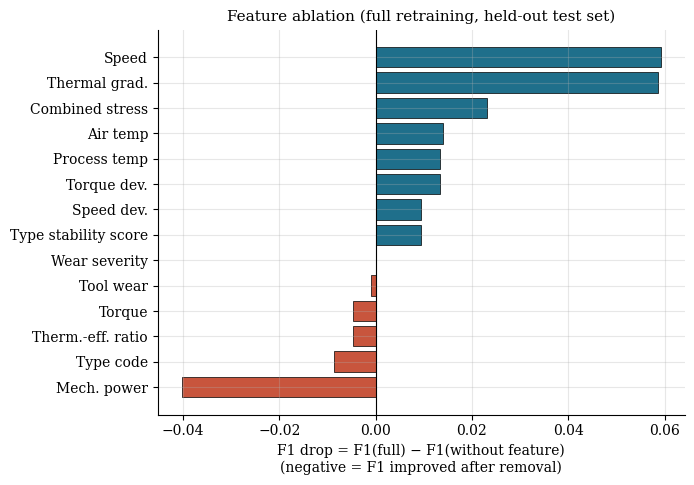

In [25]:
# Figure 11 - ablation F1-drop plot
a_ = abl_df.sort_values("F1_drop")
fig, ax = plt.subplots(figsize=(6.8, 5))
ax.barh(a_["Feature"].map(short), a_["F1_drop"], color=[PAL[2] if v < 0 else PAL[1] for v in a_["F1_drop"]], edgecolor="black", linewidth=0.5)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("F1 drop = F1(full) − F1(without feature)\n(negative = F1 improved after removal)")
ax.set_title("Feature ablation (full retraining, held-out test set)")
save_fig(fig, "fig11_ablation_f1_drop")

# 10. Global vs Type-specific Isolation Forest

* One **global** Isolation Forest and separate **Type-specific** Isolation Forests are trained on **normal (non-failure) training rows only**; the target is never an input feature.
* Inputs are standardised process features. In the primary analysis the two Type-derived columns (`Type_encoded`, score) are *excluded* so that the global model does not receive Type information that the Type-specific models cannot use;
  a sensitivity run with all 14 features is also reported.
* **Detection rate** (reported as "recall among failures") is defined as **the proportion of true machine-failure observations flagged as anomalous.** It is *not* a calibration-drift detection rate.
* "Flagged share" is the proportion of **all** observations of that Type flagged as anomalous — the alert burden. `contamination = 0.1` for every model.

In [26]:
IF_CONTAMINATION = 0.1
IF_VARIANTS = {"process features only (primary)": [c for c in ALL14 if c not in (TYPE_COL, SCORE_COL)],
               "all 14 features (sensitivity)": ALL14}
normal_mask = (ytr == 0).values
Ftr_normal = Ftr.loc[normal_mask]
print(f"Normal training rows used to fit Isolation Forests: {len(Ftr_normal)} of {len(Ftr)} training rows")

if_rows, if_flags = [], {}
for variant, cols in IF_VARIANTS.items():
    sc_if = StandardScaler().fit(Ftr_normal[cols])
    A_norm, B_test = sc_if.transform(Ftr_normal[cols]), sc_if.transform(Fte[cols])
    glob = IsolationForest(contamination=IF_CONTAMINATION, random_state=RANDOM_STATE).fit(A_norm)
    g_flag = glob.predict(B_test) == -1
    ts_flag = np.zeros(len(Fte), dtype=bool)
    for code_, tname in TYPE_NAME_MAP.items():
        m_tr = (Ftr_normal[TYPE_COL] == code_).values
        m_te = (Fte[TYPE_COL] == code_).values
        iso_t = IsolationForest(contamination=IF_CONTAMINATION, random_state=RANDOM_STATE).fit(A_norm[m_tr])
        ts_flag[m_te] = iso_t.predict(B_test[m_te]) == -1
    if_flags[variant] = {"global": g_flag, "type_specific": ts_flag}
    groups = [(tname, (Fte[TYPE_COL] == code_).values) for code_, tname in TYPE_NAME_MAP.items()] + [("All", np.ones(len(Fte), dtype=bool))]
    for tname, m_te in groups:
        yy = yte.values[m_te]; nf = int(yy.sum())
        if_rows.append({"Feature_set": variant, "Type": tname, "n_test": int(m_te.sum()), "test_failures": nf,
                        "type_specific_recall": ts_flag[m_te][yy == 1].mean() if nf else np.nan,
                        "type_specific_flagged_share": ts_flag[m_te].mean(),
                        "global_recall": g_flag[m_te][yy == 1].mean() if nf else np.nan,
                        "global_flagged_share": g_flag[m_te].mean()})
if_df = pd.DataFrame(if_rows)
display(if_df.round(3))

print("\nTrade-off summary (primary feature set) - no model is declared superior automatically:")
for r in if_df[(if_df["Feature_set"] == list(IF_VARIANTS)[0]) & (if_df["Type"] != "All")].itertuples():
    print(f"  Type {r.Type}: failures={r.test_failures} | recall: type-specific {r.type_specific_recall:.3f} vs global {r.global_recall:.3f} "
          f"(difference {r.type_specific_recall - r.global_recall:+.3f}) | flagged share: type-specific {r.type_specific_flagged_share:.3f} vs global {r.global_flagged_share:.3f} "
          f"(difference {r.type_specific_flagged_share - r.global_flagged_share:+.3f})")
print("A higher recall obtained together with a higher flagged share is a trade-off (more alerts), not an unambiguous gain. "
      "Per-Type failure counts are small, so the per-Type recalls are imprecise.")

Normal training rows used to fit Isolation Forests: 7729 of 8000 training rows


,Feature_set,Type,n_test,test_failures,type_specific_recall,type_specific_flagged_share,global_recall,global_flagged_share
0,process features only (primary),H,214,5,0.600,0.107,0.600,0.112
1,process features only (primary),L,1170,38,0.632,0.114,0.684,0.116
2,process features only (primary),M,616,25,0.560,0.112,0.560,0.119
3,process features only (primary),All,2000,68,0.603,0.112,0.632,0.116
4,all 14 features (sensitivity),H,214,5,0.600,0.117,1.000,0.397
5,all 14 features (sensitivity),L,1170,38,0.658,0.125,0.447,0.064
6,all 14 features (sensitivity),M,616,25,0.520,0.109,0.560,0.123
7,all 14 features (sensitivity),All,2000,68,0.603,0.119,0.529,0.118



Trade-off summary (primary feature set) - no model is declared superior automatically:
  Type H: failures=5 | recall: type-specific 0.600 vs global 0.600 (difference +0.000) | flagged share: type-specific 0.107 vs global 0.112 (difference -0.005)
  Type L: failures=38 | recall: type-specific 0.632 vs global 0.684 (difference -0.053) | flagged share: type-specific 0.114 vs global 0.116 (difference -0.003)
  Type M: failures=25 | recall: type-specific 0.560 vs global 0.560 (difference +0.000) | flagged share: type-specific 0.112 vs global 0.119 (difference -0.006)
A higher recall obtained together with a higher flagged share is a trade-off (more alerts), not an unambiguous gain. Per-Type failure counts are small, so the per-Type recalls are imprecise.


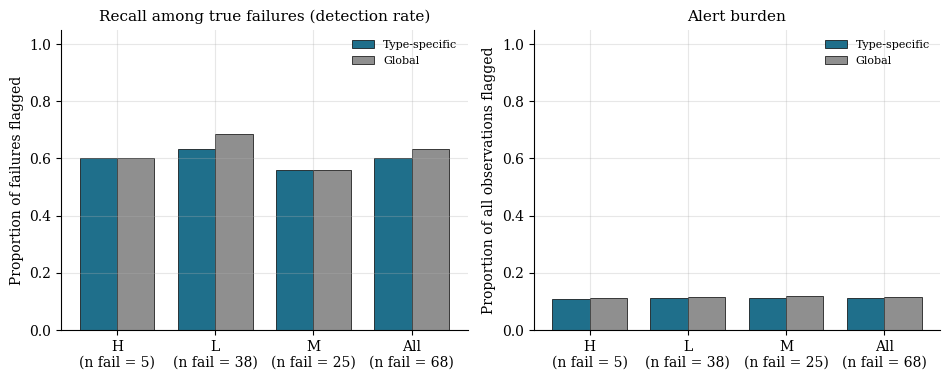

In [27]:
# Figure 12 - global vs Type-specific Isolation Forest (primary feature set)
prim = if_df[(if_df["Feature_set"] == list(IF_VARIANTS)[0])]
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.9))
xx = np.arange(len(prim)); w = 0.38
for ax, (mt, mg, ttl, yl) in zip(axes, [("type_specific_recall", "global_recall", "Recall among true failures (detection rate)", "Proportion of failures flagged"),
                                       ("type_specific_flagged_share", "global_flagged_share", "Alert burden", "Proportion of all observations flagged")]):
    ax.bar(xx - w / 2, prim[mt], w, label="Type-specific", color=PAL[1], edgecolor="black", linewidth=0.5)
    ax.bar(xx + w / 2, prim[mg], w, label="Global", color=PAL[3], edgecolor="black", linewidth=0.5)
    ax.set_xticks(xx); ax.set_xticklabels([f"{t}\n(n fail = {n})" for t, n in zip(prim["Type"], prim["test_failures"])])
    ax.set_ylabel(yl); ax.set_title(ttl); ax.set_ylim(0, 1.05); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); save_fig(fig, "fig12_global_vs_type_specific_isolation_forest")

# 11. Exploratory LSTM sensitivity analysis (corrected)

**Status: exploratory.** Because row adjacency does not establish a machine trajectory (Section 3), this model is a sensitivity analysis, not evidence of temporal degradation.

Corrections relative to the earlier version:
1. **No scaling before splitting.** The scaler is fitted on the training partition only; validation and test partitions are only transformed.
2. **No test data in training.** Early stopping and threshold selection use the **validation** partition; the test partition is evaluated once, at the end.
3. **Contiguous block partitions** of the file order (first 60 % → train, next 20 % → validation, last 20 % → test). Sequences are built **separately inside each partition**, so no sequence crosses a partition boundary.
   This protocol differs from the stratified split used elsewhere (a random split destroys row adjacency), so LSTM results are compared with XGBoost **retrained on the same blocks**, not with the Section 6 numbers.
4. **No sequence mixes product Types.** Same-Type contiguous runs are far too short (see Section 3) for windows of useful length, so sequences are built from the **Type-specific stream**: the rows of one Type, in file order, inside one partition.
   Consecutive items in such a stream are not necessarily adjacent file rows, which is why the analysis remains exploratory. The label of a sequence is the failure label of its **last** row.
5. Exact architecture: `LSTM(32) → Dropout(0.3) → Dense(16, relu) → Dropout(0.2) → Dense(1, sigmoid)`.

In [28]:
SEQ_LEN = 10
BLOCK_FRACTIONS = (0.6, 0.2)                       # train, validation; remainder = test
MAX_EPOCHS, BATCH_SIZE, ES_MONITOR, ES_PATIENCE = 60, 128, "val_loss", 8
LSTM_FEATURES = RAW5 + ["thermal_gradient", "mechanical_power"]     # point-wise features that need no fitted parameters

df_ord = df_model.sort_index()
n_rows = len(df_ord); i1, i2 = int(round(BLOCK_FRACTIONS[0] * n_rows)), int(round(sum(BLOCK_FRACTIONS) * n_rows))
blocks = {"train": df_ord.iloc[:i1], "val": df_ord.iloc[i1:i2], "test": df_ord.iloc[i2:]}
print("Contiguous block partitions (file order):")
for k, v in blocks.items():
    print(f"  {k:5s}: rows {v.index.min()}-{v.index.max()} | n = {len(v)} | failures = {int(v[TARGET].sum())} ({v[TARGET].mean():.4f})")
assert all(v[TARGET].sum() > 0 for v in blocks.values()), "a partition has no failures"
assert blocks["train"].index.max() < blocks["val"].index.min() and blocks["val"].index.max() < blocks["test"].index.min()

def lstm_point_features(d):
    f = d[RAW5].copy()
    f["thermal_gradient"] = d["Process temperature [K]"] - d["Air temperature [K]"]
    f["mechanical_power"] = d["Rotational speed [rpm]"] * d["Torque [Nm]"]
    return f[LSTM_FEATURES]

scaler_lstm = StandardScaler().fit(lstm_point_features(blocks["train"]))          # training partition ONLY
assert scaler_lstm.n_samples_seen_ == len(blocks["train"])
scaled = {k: scaler_lstm.transform(lstm_point_features(v)) for k, v in blocks.items()}

def make_type_stream_sequences(d, Xs, seq_len):
    """Sliding windows inside ONE partition and ONE Type stream (rows of that Type in file order)."""
    Xo, yo, eo, to = [], [], [], []
    y_arr, idx_arr = d[TARGET].values, d.index.values
    for t in sorted(d[TYPE_COL].unique()):
        pos = np.where(d[TYPE_COL].values == t)[0]
        if len(pos) < seq_len: continue
        win = np.arange(len(pos) - seq_len + 1)[:, None] + np.arange(seq_len)[None, :]
        rows = pos[win]
        Xo.append(Xs[rows]); last = rows[:, -1]
        yo.append(y_arr[last]); eo.append(idx_arr[last]); to.append(np.full(len(last), t))
    return {"X": np.concatenate(Xo).astype("float32"), "y": np.concatenate(yo).astype("float32"),
            "end_idx": np.concatenate(eo), "type": np.concatenate(to)}

seqs = {k: make_type_stream_sequences(blocks[k], scaled[k], SEQ_LEN) for k in blocks}
print(f"\nSequence length = {SEQ_LEN}; features per step = {len(LSTM_FEATURES)} -> input shape (timesteps, features) = ({SEQ_LEN}, {len(LSTM_FEATURES)})")
for k, s in seqs.items():
    per_type = {TYPE_NAME_MAP[int(t)]: int((s["type"] == t).sum()) for t in np.unique(s["type"])}
    print(f"  {k:5s} sequences X{s['X'].shape} y{s['y'].shape} | failures (last-row label) = {int(s['y'].sum())} | per Type {per_type}")

# how many windows would exist if sequences had to be strictly contiguous same-Type file rows?
for k, v in blocks.items():
    tv = v["Type"].values if "Type" in v else v[TYPE_COL].values
    rid = pd.Series(tv != np.r_[tv[0], tv[:-1]]).cumsum()
    rl = rid.value_counts()
    print(f"  {k:5s}: strictly contiguous same-Type windows of length {SEQ_LEN} = {int(np.clip(rl - SEQ_LEN + 1, 0, None).sum())} (mean run length {rl.mean():.2f}) "
          f"-> contiguous-only sequences are not feasible, hence the Type-stream construction")
assert len(set(seqs["train"]["end_idx"]) & set(seqs["val"]["end_idx"])) == 0 and len(set(seqs["val"]["end_idx"]) & set(seqs["test"]["end_idx"])) == 0

Contiguous block partitions (file order):
  train: rows 0-5999 | n = 6000 | failures = 255 (0.0425)
  val  : rows 6000-7999 | n = 2000 | failures = 45 (0.0225)
  test : rows 8000-9999 | n = 2000 | failures = 39 (0.0195)

Sequence length = 10; features per step = 7 -> input shape (timesteps, features) = (10, 7)
  train sequences X(5973, 10, 7) y(5973,) | failures (last-row label) = 255 | per Type {'H': 592, 'L': 3599, 'M': 1782}
  val   sequences X(1973, 10, 7) y(1973,) | failures (last-row label) = 45 | per Type {'H': 172, 'L': 1199, 'M': 602}
  test  sequences X(1973, 10, 7) y(1973,) | failures (last-row label) = 39 | per Type {'H': 212, 'L': 1175, 'M': 586}
  train: strictly contiguous same-Type windows of length 10 = 61 (mean run length 1.91) -> contiguous-only sequences are not feasible, hence the Type-stream construction
  val  : strictly contiguous same-Type windows of length 10 = 7 (mean run length 1.84) -> contiguous-only sequences are not feasible, hence the Type-stream constr

In [42]:
# XGBoost retrained on the SAME block partitions (point-wise 14-feature pipeline) -> aligned probabilities for the sequence-end rows
xgb_blk = make_pipe(make_xgb()).fit(blocks["train"][PREDICTORS_RAW], blocks["train"][TARGET])
assert set(xgb_blk.named_steps["fe"].fit_index_) <= set(blocks["train"].index)
p_xgb_blk = {k: pd.Series(xgb_blk.predict_proba(blocks[k][PREDICTORS_RAW])[:, 1], index=blocks[k].index).loc[seqs[k]["end_idx"]].values
             for k in ("train", "val", "test")}
print("Block-protocol XGBoost fitted on the training block; probabilities extracted for the sequence-end rows of every partition.")

TF_AVAILABLE = False
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
    tf.keras.utils.set_random_seed(RANDOM_STATE)
    try:
        tf.config.experimental.enable_op_determinism()
    except Exception as e:
        print("op determinism not enabled:", type(e).__name__)
    TF_AVAILABLE = True
    print("TensorFlow", tf.__version__)
except Exception as e:
    print("TensorFlow not available -> LSTM training, ensemble, Fig. 14 and LSTM rows of Table 10 are skipped:", type(e).__name__)

Block-protocol XGBoost fitted on the training block; probabilities extracted for the sequence-end rows of every partition.
TensorFlow 2.21.0


In [43]:
lstm_res = None
if TF_AVAILABLE:
    ytr_s, yva_s, yte_s = seqs["train"]["y"], seqs["val"]["y"], seqs["test"]["y"]
    cw_vals = compute_class_weight("balanced", classes=np.array([0.0, 1.0]), y=ytr_s)
    class_weight = {0: float(cw_vals[0]), 1: float(cw_vals[1])}

    model_lstm = keras.Sequential([
        layers.Input(shape=(SEQ_LEN, len(LSTM_FEATURES))),
        layers.LSTM(32),
        layers.Dropout(0.3),
        layers.Dense(16, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(1, activation="sigmoid")])
    model_lstm.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
                       metrics=[keras.metrics.Recall(name="recall"), keras.metrics.AUC(name="roc_auc"), keras.metrics.AUC(curve="PR", name="pr_auc")])
    model_lstm.summary()
    n_trainable = int(sum(np.prod(w.shape) for w in model_lstm.trainable_weights))
    print("Trainable parameters:", n_trainable, "| input shape:", model_lstm.input_shape)
    print("Sequence shapes -> train", seqs["train"]["X"].shape, "| validation", seqs["val"]["X"].shape, "| test", seqs["test"]["X"].shape)
    print("Class weights (from training sequences):", {k: round(v, 3) for k, v in class_weight.items()})
    print(f"Max epochs = {MAX_EPOCHS} | batch size = {BATCH_SIZE} | early-stopping monitor = {ES_MONITOR} (validation) | patience = {ES_PATIENCE} | restore best weights = True")

    es = keras.callbacks.EarlyStopping(monitor=ES_MONITOR, patience=ES_PATIENCE, restore_best_weights=True, mode="min")
    hist = model_lstm.fit(seqs["train"]["X"], ytr_s, validation_data=(seqs["val"]["X"], yva_s), epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
                          class_weight=class_weight, callbacks=[es], verbose=0, shuffle=True)
    H = hist.history
    best_epoch = int(np.argmin(H["val_loss"])) + 1
    stop_epoch = len(H["loss"])
    print(f"\nBest epoch (min validation loss) = {best_epoch} | stopping epoch = {stop_epoch}")

    p_l = {k: model_lstm.predict(seqs[k]["X"], verbose=0).ravel() for k in ("train", "val", "test")}
    thr_lstm, f1_val_lstm = best_f1_threshold(yva_s, p_l["val"])                 # validation only
    lstm_test = evaluate(yte_s, (p_l["test"] >= thr_lstm).astype(int), p_l["test"])
    lstm_val_at_thr = evaluate(yva_s, (p_l["val"] >= thr_lstm).astype(int), p_l["val"])
    print(f"Decision threshold (F1-optimal on VALIDATION, frozen) = {thr_lstm:.4f} | validation F1 = {f1_val_lstm:.4f}")
    print("Held-out test confusion matrix [[TN, FP], [FN, TP]] =", cm_of(lstm_test))
    for m in METRICS: print(f"  test {m:9s} = {lstm_test[m]:.4f}")

    recall_rows = [
        ("Training recall (Keras metric, threshold 0.5, at best epoch)", H["recall"][best_epoch - 1]),
        ("Peak validation recall (Keras metric, threshold 0.5, max over epochs)", float(np.max(H["val_recall"]))),
        ("Final validation recall (Keras metric, threshold 0.5, last epoch before restoring best weights)", H["val_recall"][-1]),
        ("Validation recall of the restored model at the frozen validation-selected threshold", lstm_val_at_thr["Recall"]),
        ("Held-out TEST recall at the frozen threshold", lstm_test["Recall"])]
    recall_df = pd.DataFrame(recall_rows, columns=["Quantity", "Recall"])
    print("\nFour distinct recall quantities (do not interchange them):")
    display(recall_df.round(4))
    lstm_res = {"best_epoch": best_epoch, "stop_epoch": stop_epoch, "thr": thr_lstm, "test": lstm_test, "n_trainable": n_trainable}
else:
    print("LSTM section skipped (TensorFlow not installed).")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 32)                  │           5,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,665 (22.13 KB)

 Trainable params: 5,665 (22.13 KB)

 Non-trainable params: 0 (0.00 B)

Trainable parameters: 5665 | input shape: (None, 10, 7)
Sequence shapes -> train (5973, 10, 7) | validation (1973, 10, 7) | test (1973, 10, 7)
Class weights (from training sequences): {0: 0.522, 1: 11.712}
Max epochs = 60 | batch size = 128 | early-stopping monitor = val_loss (validation) | patience = 8 | restore best weights = True

Best epoch (min validation loss) = 48 | stopping epoch = 56
Decision threshold (F1-optimal on VALIDATION, frozen) = 0.8487 | validation F1 = 0.6000
Held-out test confusion matrix [[TN, FP], [FN, TP]] = [[1928, 6], [21, 18]]
  test F1        = 0.5714
  test Recall    = 0.4615
  test Precision = 0.7500
  test MCC       = 0.5821
  test ROC_AUC   = 0.9455
  test PR_AUC    = 0.6531

Four distinct recall quantities (do not interchange them):


,Quantity,Recall
0,"Training recall (Keras metric, threshold 0.5, ...",0.9490
1,"Peak validation recall (Keras metric, threshol...",0.8222
2,"Final validation recall (Keras metric, thresho...",0.7556
3,Validation recall of the restored model at the...,0.5333
4,Held-out TEST recall at the frozen threshold,0.4615


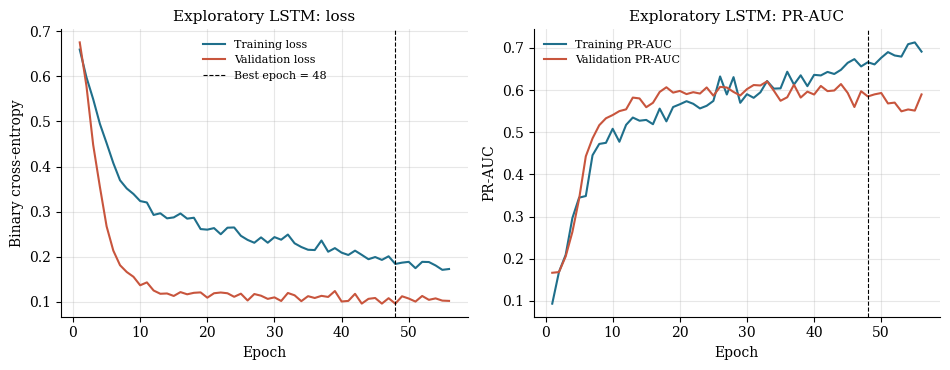

In [44]:
# Figure 14 - LSTM training/validation curves (only if the LSTM was trained)
if TF_AVAILABLE and lstm_res is not None:
    fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8))
    ep = np.arange(1, stop_epoch + 1)
    axes[0].plot(ep, H["loss"], color=PAL[1], label="Training loss"); axes[0].plot(ep, H["val_loss"], color=PAL[2], label="Validation loss")
    axes[0].axvline(best_epoch, color="black", ls="--", lw=0.8, label=f"Best epoch = {best_epoch}")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Binary cross-entropy"); axes[0].set_title("Exploratory LSTM: loss"); axes[0].legend(frameon=False, fontsize=8)
    axes[1].plot(ep, H["pr_auc"], color=PAL[1], label="Training PR-AUC"); axes[1].plot(ep, H["val_pr_auc"], color=PAL[2], label="Validation PR-AUC")
    axes[1].axvline(best_epoch, color="black", ls="--", lw=0.8)
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("PR-AUC"); axes[1].set_title("Exploratory LSTM: PR-AUC"); axes[1].legend(frameon=False, fontsize=8)
    fig.tight_layout(); save_fig(fig, "fig14_lstm_training_validation_curves")
else:
    print("Figure 14 skipped (LSTM not trained).")

# 12. Probability-level ensemble (replaces the invalid metric-averaging)

The earlier version averaged metrics (e.g. `0.5·F1_xgb + 0.5·F1_lstm`). That has no statistical meaning and has been removed.
Here the ensemble is formed from probabilities, `p_ens = w·p_xgb + (1 − w)·p_lstm`, on the **same sequence-end rows**; the weight and the decision threshold are selected on the **validation** partition only,
and all test metrics are then computed independently from `p_ens`. XGBoost (block protocol) and the LSTM are evaluated on exactly the same rows. If XGBoost alone is better, that is reported as is.

In [45]:
ens_res, block_df = None, None
yva_seq, yte_seq = seqs["val"]["y"], seqs["test"]["y"]

# XGBoost alone, block protocol (threshold from validation)
thr_xb, _ = best_f1_threshold(yva_seq, p_xgb_blk["val"])
xgb_blk_test = evaluate(yte_seq, (p_xgb_blk["test"] >= thr_xb).astype(int), p_xgb_blk["test"])
block_rows = [{"Model": "XGBoost (block protocol)", "Threshold (validation-selected)": thr_xb, **{m: xgb_blk_test[m] for m in METRICS},
               "TN": xgb_blk_test["TN"], "FP": xgb_blk_test["FP"], "FN": xgb_blk_test["FN"], "TP": xgb_blk_test["TP"]}]

if TF_AVAILABLE and lstm_res is not None:
    block_rows.append({"Model": "LSTM (exploratory)", "Threshold (validation-selected)": thr_lstm, **{m: lstm_test[m] for m in METRICS},
                       "TN": lstm_test["TN"], "FP": lstm_test["FP"], "FN": lstm_test["FN"], "TP": lstm_test["TP"]})
    w_grid = np.round(np.arange(0.0, 1.0001, 0.05), 2)
    val_ap = np.array([average_precision_score(yva_seq, w * p_xgb_blk["val"] + (1 - w) * p_l["val"]) for w in w_grid])
    w_xgb = float(w_grid[int(np.argmax(val_ap))]); w_lstm = float(round(1 - w_xgb, 2))        # chosen on validation PR-AUC
    p_ens_val = w_xgb * p_xgb_blk["val"] + w_lstm * p_l["val"]
    p_ens_test = w_xgb * p_xgb_blk["test"] + w_lstm * p_l["test"]
    thr_ens, _ = best_f1_threshold(yva_seq, p_ens_val)
    ens_test = evaluate(yte_seq, (p_ens_test >= thr_ens).astype(int), p_ens_test)
    block_rows.append({"Model": f"Ensemble (w_xgb={w_xgb:.2f}, w_lstm={w_lstm:.2f})", "Threshold (validation-selected)": thr_ens, **{m: ens_test[m] for m in METRICS},
                       "TN": ens_test["TN"], "FP": ens_test["FP"], "FN": ens_test["FN"], "TP": ens_test["TP"]})
    ens_res = {"w_xgb": w_xgb, "w_lstm": w_lstm, "thr": thr_ens, "test": ens_test, "val_ap": val_ap, "w_grid": w_grid}

block_df = pd.DataFrame(block_rows)
print("Block-protocol comparison on identical test sequence-end rows (weights/thresholds chosen on validation only):")
display(block_df.round(4))

if ens_res is not None:
    best_f1_row = block_df.loc[block_df["F1"].idxmax(), "Model"]; best_pr_row = block_df.loc[block_df["PR_AUC"].idxmax(), "Model"]
    print(f"\nHighest test F1: {best_f1_row} | highest test PR-AUC: {best_pr_row}")
    if "XGBoost" in best_f1_row and "XGBoost" in best_pr_row and "Ensemble" not in best_f1_row:
        print("XGBoost alone performs best on both F1 and PR-AUC in this protocol; the ensemble is NOT adopted.")
    elif "Ensemble" in best_f1_row or "Ensemble" in best_pr_row:
        print("The ensemble is best on at least one headline metric; the differences should be judged against sampling uncertainty (few test failures) before any claim is made.")
    else:
        print("The exploratory LSTM is best on at least one headline metric; interpret cautiously (exploratory, row-adjacency based).")
else:
    print("\nEnsemble skipped (TensorFlow not available); only the XGBoost block-protocol result is reported.")

Block-protocol comparison on identical test sequence-end rows (weights/thresholds chosen on validation only):


,Model,Threshold (validation-selected),F1,Recall,Precision,MCC,ROC_AUC,PR_AUC,TN,FP,FN,TP
0,XGBoost (block protocol),0.8905,0.6667,0.5385,0.8750,0.6818,0.9322,0.6569,1931,3,18,21
1,LSTM (exploratory),0.8487,0.5714,0.4615,0.7500,0.5821,0.9455,0.6531,1928,6,21,18
2,"Ensemble (w_xgb=0.45, w_lstm=0.55)",0.7595,0.6557,0.5128,0.9091,0.6784,0.9530,0.7460,1932,2,19,20



Highest test F1: XGBoost (block protocol) | highest test PR-AUC: Ensemble (w_xgb=0.45, w_lstm=0.55)
The ensemble is best on at least one headline metric; the differences should be judged against sampling uncertainty (few test failures) before any claim is made.


# 13. Manuscript-ready tables (all computed, exported to `outputs/tables/`)

In [46]:
# Table 1 - dataset characteristics
t1 = [("Dataset", "AI4I 2020 Predictive Maintenance (simulated benchmark)"),
      ("Observations", len(raw)), ("Columns in raw file", raw.shape[1]),
      ("Raw predictors used", ", ".join(PREDICTORS_RAW)), ("Engineered process-stability features", len(ENG_FEATURES)),
      ("Type-associated stability score", SCORE_COL), ("Target", TARGET),
      ("Machine failures (n)", n_fail), ("Failure prevalence", n_fail / n_total),
      ("Product Type counts (L / M / H)", f"{type_counts['L']} / {type_counts['M']} / {type_counts['H']}"),
      ("Excluded leakage columns", ", ".join(LEAKAGE_COLS)), ("Excluded identifier columns", ", ".join(ID_COLS)),
      ("Train / test split", f"{len(Xtr)} / {len(Xte)} (stratified, random_state={RANDOM_STATE})"),
      ("Training failures", int(ytr.sum())), ("Test failures", int(yte.sum())),
      ("Test failure prevalence", float(yte.mean()))]
table1 = save_table(pd.DataFrame(t1, columns=["Characteristic", "Value"]).astype({"Value": object}), "table1_dataset_characteristics")

# Table 2 - product-Type failure distribution
table2 = type_tbl.reset_index().rename(columns={"Type": "Product_Type"})
table2["chi2_p_value_Type_vs_failure"] = np.nan
table2.loc[len(table2)] = {"Product_Type": "All", "n": n_total, "failures": n_fail, "failure_rate": n_fail / n_total,
                           "ci95_low": wilson_ci(n_fail, n_total)[0], "ci95_high": wilson_ci(n_fail, n_total)[1], "chi2_p_value_Type_vs_failure": chi2_p}
save_table(table2, "table2_product_type_failure_distribution")

table3 = save_table(bench_df, "table3_model_benchmarking")
table4 = save_table(table4, "table4_five_fold_cross_validation")
table5 = save_table(boot_df, "table5_bootstrap_95ci_xgboost")
table6 = save_table(dep_df, "table6_feature_set_dependency")
table7 = save_table(abl_df, "table7_feature_ablation")
save_table(perm_df, "table7b_permutation_importance")
table8 = save_table(if_df, "table8_global_vs_type_specific_isolation_forest")
table9 = save_table(table9, "table9_threshold_analysis")

# Table 10 - LSTM details / performance (exploratory)
if TF_AVAILABLE and lstm_res is not None:
    t10 = [("Status", "Exploratory sensitivity analysis (row adjacency not validated as a machine trajectory)"),
           ("Architecture", "LSTM(32) -> Dropout(0.3) -> Dense(16, relu) -> Dropout(0.2) -> Dense(1, sigmoid)"),
           ("Trainable parameters", lstm_res["n_trainable"]), ("Input shape (timesteps, features)", f"({SEQ_LEN}, {len(LSTM_FEATURES)})"),
           ("Input features", ", ".join(LSTM_FEATURES)),
           ("Partitions (contiguous blocks, train/val/test)", f"{len(blocks['train'])} / {len(blocks['val'])} / {len(blocks['test'])} rows"),
           ("Train sequences shape", str(seqs["train"]["X"].shape)), ("Validation sequences shape", str(seqs["val"]["X"].shape)), ("Test sequences shape", str(seqs["test"]["X"].shape)),
           ("Class weights", str({k: round(v, 3) for k, v in class_weight.items()})),
           ("Maximum epochs", MAX_EPOCHS), ("Batch size", BATCH_SIZE), ("Early-stopping monitor", ES_MONITOR + " (validation partition)"), ("Patience", ES_PATIENCE),
           ("Best epoch", best_epoch), ("Stopping epoch", stop_epoch), ("Decision threshold (validation-selected)", lstm_res["thr"]),
           ("Confusion matrix [[TN, FP], [FN, TP]] (test)", str(cm_of(lstm_test)))]
    t10 += [(f"Test {m}", lstm_test[m]) for m in METRICS]
    t10 += [(q, r) for q, r in recall_rows]
    table10 = pd.DataFrame(t10, columns=["Item", "Value"]).astype({"Value": object})
else:
    table10 = pd.DataFrame([("Status", "LSTM not run (TensorFlow not available)")], columns=["Item", "Value"])
save_table(table10, "table10_lstm_details_performance")
table10b = save_table(block_df, "table10b_block_protocol_xgboost_lstm_ensemble")

print("Exported tables:", sorted(p.name for p in TAB_DIR.glob("*.csv")))

Exported tables: ['table10_lstm_details_performance.csv', 'table10b_block_protocol_xgboost_lstm_ensemble.csv', 'table1_dataset_characteristics.csv', 'table2_product_type_failure_distribution.csv', 'table3_model_benchmarking.csv', 'table4_five_fold_cross_validation.csv', 'table5_bootstrap_95ci_xgboost.csv', 'table6_feature_set_dependency.csv', 'table7_feature_ablation.csv', 'table7b_permutation_importance.csv', 'table8_global_vs_type_specific_isolation_forest.csv', 'table9_threshold_analysis.csv']


# 14. Reproducibility Checks

Every assertion recomputes a quantity from the underlying objects and compares it with what the tables/figures report. The success message is printed **only if all checks pass**.

In [47]:
CHECK_COUNT = 0   # reset: count only checks run in this section

# ---- data / split / leakage ----
chk(len(raw) == n_total == 10000, "number of observations")
chk((type_counts["L"], type_counts["M"], type_counts["H"]) == (6000, 2997, 1003), "Type counts L/M/H")
chk(int(table2.loc[table2.Product_Type == "L", "n"].iloc[0]) == int((raw.Type == "L").sum()) == 6000, "Table 2 L count")
chk(int(table2.loc[table2.Product_Type == "M", "n"].iloc[0]) == int((raw.Type == "M").sum()) == 2997, "Table 2 M count")
chk(int(table2.loc[table2.Product_Type == "H", "n"].iloc[0]) == int((raw.Type == "H").sum()) == 1003, "Table 2 H count")
chk(table2.loc[table2.Product_Type != "All", "failures"].sum() == n_fail == int(raw[TARGET].sum()), "failure counts by Type sum to the total")
for t in ["H", "L", "M"]:
    chk(np.isclose(table2.loc[table2.Product_Type == t, "failure_rate"].iloc[0], raw.loc[raw.Type == t, TARGET].mean()), f"Table 2 failure rate {t}")
chk(TYPE_CODE_MAP == {"H": 0, "L": 1, "M": 2} and list(le.classes_) == ["H", "L", "M"], "label encoding H0 L1 M2")
chk(len(train_idx) + len(test_idx) == len(raw) and not (set(train_idx) & set(test_idx)), "split exhaustive and disjoint")
chk(len(Xte) == int(round(TEST_SIZE * len(raw))) and len(Xtr) == len(raw) - len(Xte), "80/20 split sizes")
chk(int(ytr.sum()) + int(yte.sum()) == n_fail, "training + test failures == total failures")
chk(set(fe_main.fit_index_) == set(train_idx), "feature builder fitted on training rows only")
chk(set(model_xgb.named_steps["fe"].fit_index_) == set(train_idx), "final pipeline feature step fitted on training rows only")
chk(not (set(ALL14) & set(LEAKAGE_COLS + [TARGET] + ID_COLS)), "no leakage/target/identifier columns among predictors")
chk(fe_true.score_map_ == fe_shuf.score_map_, "derived predictors do not depend on Machine failure")
chk(n_unique_score == 3 and max_within_type_sd == 0, "score has 3 unique values and is constant within Type")
chk(abs(score_tbl[SCORE_COL].values - np.array([fe_main.score_map_[k] for k in score_tbl["Type_encoded"]])).max() == 0, "score table equals fitted map")

# ---- XGBoost test metrics vs confusion matrix ----
chk(TN + FP + FN + TP == len(Xte), "TN+FP+FN+TP == len(test set)")
chk(TP + FN == int(yte.sum()) and TN + FP == int((yte == 0).sum()), "confusion-matrix margins equal test class counts")
chk(np.isclose(precision_score(yte, p_def), TP / (TP + FP)) and np.isclose(table3.set_index("Model").loc[MAIN_MODEL, "Precision"], TP / (TP + FP)), "precision == TP/(TP+FP)")
chk(np.isclose(recall_score(yte, p_def), TP / (TP + FN)) and np.isclose(table3.set_index("Model").loc[MAIN_MODEL, "Recall"], TP / (TP + FN)), "recall == TP/(TP+FN)")
chk(np.isclose(f1_score(yte, p_def), 2 * TP / (2 * TP + FP + FN)) and np.isclose(table3.set_index("Model").loc[MAIN_MODEL, "F1"], f1_score(yte, p_def)), "F1 consistency")
chk(np.isclose(table3.set_index("Model").loc[MAIN_MODEL, "MCC"], matthews_corrcoef(yte, p_def)), "MCC consistency")
chk(np.isclose(table3.set_index("Model").loc[MAIN_MODEL, "PR_AUC"], average_precision_score(yte, pr_xgb)) and
    np.isclose(table3.set_index("Model").loc[MAIN_MODEL, "ROC_AUC"], roc_auc_score(yte, pr_xgb)), "AUC consistency")

# ---- Table 3: every model row recomputed from stored predictions ----
for _, r in table3.iterrows():
    e = evaluate(yte, preds[r["Model"]], probas[r["Model"]])
    chk(all(np.isclose(r[m], e[m]) for m in METRICS) and all(int(r[c]) == e[c] for c in ["TN", "FP", "FN", "TP"]), f"Table 3 row {r['Model']}")
    chk(e["TN"] + e["FP"] + e["FN"] + e["TP"] == len(yte), f"Table 3 confusion sum {r['Model']}")
chk(len(table3) == 7, "seven benchmarked models")

# ---- Table 4: cross-validation ----
for name, df_cv in cv_raw.items():
    t = table4[table4.Model == name].set_index("Row")
    chk(len(df_cv) == 5 and int(df_cv["n_failures"].sum()) == int(ytr.sum()), f"CV folds cover all training failures ({name})")
    for m in METRICS:
        chk(np.isclose(float(t.loc["Mean", m]), df_cv[m].mean()) and np.isclose(float(t.loc["SD (ddof=0)", m]), df_cv[m].std(ddof=SD_DDOF)), f"Table 4 mean/SD {name} {m}")
        chk(t.loc["Mean ± SD", m] == f"{df_cv[m].mean():.4f} ± {df_cv[m].std(ddof=SD_DDOF):.4f}", f"Table 4 'Mean ± SD' string {name} {m}")
        for k in range(1, 6):
            chk(np.isclose(float(t.loc[f"Fold {k}", m]), df_cv.loc[k, m]), f"Table 4 fold {k} {name} {m}")

# ---- Table 5: bootstrap ----
chk(len(boot_vals) >= 1000 and N_BOOT >= 1000, "at least 1000 bootstrap samples")
for _, r in table5.iterrows():
    chk(r["CI95_low"] <= r["CI95_high"] and r["CI95_low"] - 1e-9 <= r["Point_estimate"] <= r["CI95_high"] + 1e-9, f"bootstrap interval brackets point estimate ({r['Metric']})")
    chk(np.isclose(r["Point_estimate"], xgb_def[r["Metric"]]), f"Table 5 point estimate {r['Metric']}")
    j = BOOT_METRICS.index(r["Metric"])
    chk(np.isclose(r["CI95_low"], np.percentile(boot_vals[:, j], 2.5)) and np.isclose(r["CI95_high"], np.percentile(boot_vals[:, j], 97.5)), f"Table 5 percentiles {r['Metric']}")

# ---- Table 6: dependency analysis ----
for _, r in table6.iterrows():
    f = dep_folds[r["Feature set"]]
    chk(np.isclose(r["F1_mean"], f["F1"].mean()) and np.isclose(r["F1_SD"], f["F1"].std(ddof=SD_DDOF)) and
        np.isclose(r["PR_AUC_mean"], f["PR_AUC"].mean()) and np.isclose(r["ROC_AUC_mean"], f["ROC_AUC"].mean()), f"Table 6 {r['Feature set']}")
chk(len(table6) == 6 and len(dep_folds["raw5"]["F1"]) == rcv.get_n_splits(), "Table 6 rows / folds")

# ---- Threshold analysis (Table 9) ----
chk(np.isclose(thr_oof, best_f1_threshold(ytr, oof)[0]) and FINAL_THRESHOLD == thr_oof, "final threshold equals the training-OOF-selected threshold")
chk(FINAL_THRESHOLD != thr_test_opt or np.isclose(thr_oof, thr_test_opt), "final threshold is not silently replaced by the test-optimised one")
r9 = table9.set_index("Setting")
chk(np.isclose(r9.loc["Test @ OOF-selected threshold (final)", "F1"], f1_score(yte, pr_xgb >= FINAL_THRESHOLD)), "Table 9 OOF-threshold F1")
chk(np.isclose(r9.loc["Test @ OOF-selected threshold (final)", "Threshold"], FINAL_THRESHOLD), "Table 9 threshold value")
chk(np.isclose(r9.loc["Test @ default 0.5", "F1"], xgb_def["F1"]), "Table 9 default F1")
chk(np.isclose(r9.loc[TEST_OPT_LABEL, "F1"], f1_test_opt) and r9.loc[TEST_OPT_LABEL, "Threshold_source"].startswith("TEST SET"), "Table 9 test-optimised row is labelled diagnostic")
chk(np.isclose(r9.loc["Training OOF (selection set)", "F1"], f1_oof), "Table 9 OOF F1")
for s in r9.index:
    chk(int(r9.loc[s, ["TN", "FP", "FN", "TP"]].sum()) in (len(yte), len(ytr)), f"Table 9 confusion sum ({s})")

# ---- Table 7: ablation ----
chk(len(table7) == len(ALL14) and set(table7["Feature"]) == set(ALL14), "ablation covers every feature once")
chk(all(np.isclose(table7["F1_drop"], table7["Baseline_F1_full_model"] - table7["F1_without_feature"])), "F1 drop == baseline - ablated F1")
chk(np.allclose(table7["Baseline_F1_full_model"], xgb_def["F1"]), "ablation baseline equals Table 3 XGBoost F1")

# ---- Table 8: Isolation Forest ----
prim_ = table8[table8["Feature_set"] == list(IF_VARIANTS)[0]]
chk(prim_.loc[prim_["Type"] != "All", "test_failures"].sum() == int(yte.sum()) and prim_.loc[prim_["Type"] != "All", "n_test"].sum() == len(yte), "Table 8 counts sum to test totals")
for variant in IF_VARIANTS:
    fl = if_flags[variant]
    for tname in ["H", "L", "M"]:
        mk = (Fte[TYPE_COL] == TYPE_CODE_MAP[tname]).values; yy = yte.values[mk]
        row = table8[(table8.Feature_set == variant) & (table8.Type == tname)].iloc[0]
        chk(np.isclose(row["type_specific_recall"], fl["type_specific"][mk][yy == 1].mean()) and np.isclose(row["global_recall"], fl["global"][mk][yy == 1].mean()), f"Table 8 recall {variant} {tname}")
        chk(np.isclose(row["type_specific_flagged_share"], fl["type_specific"][mk].mean()) and np.isclose(row["global_flagged_share"], fl["global"][mk].mean()), f"Table 8 flagged {variant} {tname}")
        chk(int(row["test_failures"]) == int(yy.sum()), f"Table 8 failures {variant} {tname}")
chk(int(Ftr_normal[TYPE_COL].shape[0]) == int((ytr == 0).sum()), "Isolation Forests trained on normal training rows only")

# ---- LSTM / ensemble checks (if run) ----
chk(blocks["train"].index.max() < blocks["val"].index.min() and blocks["val"].index.max() < blocks["test"].index.min(), "LSTM partitions are disjoint contiguous blocks")
chk(scaler_lstm.n_samples_seen_ == len(blocks["train"]), "LSTM scaler fitted on training partition only")
chk(set(xgb_blk.named_steps["fe"].fit_index_) <= set(blocks["train"].index), "block-protocol XGBoost fitted on training block only")
chk(all(seqs[k]["X"].shape[1:] == (SEQ_LEN, len(LSTM_FEATURES)) for k in seqs), "sequence shapes")
chk(set(seqs["test"]["end_idx"]) <= set(blocks["test"].index) and set(seqs["val"]["end_idx"]) <= set(blocks["val"].index) and set(seqs["train"]["end_idx"]) <= set(blocks["train"].index), "no sequence crosses a partition boundary")
chk(sum(block_df[["TN", "FP", "FN", "TP"]].iloc[0]) == len(seqs["test"]["y"]), "block-protocol XGBoost confusion matrix covers all test sequences")
if TF_AVAILABLE and lstm_res is not None:
    cmL = np.array(cm_of(lstm_test)); TNl, FPl, FNl, TPl = cmL.ravel()
    chk(TNl + FPl + FNl + TPl == len(seqs["test"]["y"]), "LSTM confusion sum == number of test sequences")
    chk(np.isclose(lstm_test["Precision"], TPl / (TPl + FPl) if TPl + FPl else 0.0) and np.isclose(lstm_test["Recall"], TPl / (TPl + FNl)), "LSTM precision/recall from confusion matrix")
    chk(model_lstm.layers[0].units == 32 and abs(model_lstm.layers[1].rate - 0.3) < 1e-9 and model_lstm.layers[2].units == 16 and
        model_lstm.layers[2].activation.__name__ == "relu" and abs(model_lstm.layers[3].rate - 0.2) < 1e-9 and model_lstm.layers[4].units == 1, "exact LSTM architecture")
    chk(ES_MONITOR.startswith("val_"), "early stopping monitors a validation quantity")
    chk(np.isclose(table10.set_index("Item").loc["Test Recall", "Value"], lstm_test["Recall"]), "Table 10 recall")
    chk(w_xgb == ens_res["w_grid"][int(np.argmax(ens_res["val_ap"]))] and np.isclose(w_xgb + w_lstm, 1.0), "ensemble weight selected on validation only")
    e2 = evaluate(yte_seq, (ens_res["w_xgb"] * p_xgb_blk["test"] + ens_res["w_lstm"] * p_l["test"] >= ens_res["thr"]).astype(int), ens_res["w_xgb"] * p_xgb_blk["test"] + ens_res["w_lstm"] * p_l["test"])
    chk(all(np.isclose(e2[m], ens_res["test"][m]) for m in METRICS), "ensemble metrics recomputed from probabilities")

# ---- terminology / outputs ----
def _contains_forbidden(df):
    s = " ".join(map(str, df.columns)) + " " + " ".join(df.astype(str).values.ravel())
    return "supplier" in s.lower()
chk(not any(_contains_forbidden(t) for t in TABLES.values()), "no forbidden terminology in any table")
chk(not _contains_forbidden(pd.DataFrame({"x": list(short.values()) + ALL14})), "no forbidden terminology in feature labels")
for name in TABLES: chk((TAB_DIR / f"{name}.csv").exists(), f"table file exists: {name}")
for name in FIG_LOG: chk((FIG_DIR / f"{name}.png").exists() and (FIG_DIR / f"{name}.pdf").exists(), f"figure files exist: {name}")
chk(len(FIG_LOG) >= 12, "figures saved")

print(f"{CHECK_COUNT} individual checks executed.")
print("ALL NUMERICAL CONSISTENCY CHECKS PASSED")

225 individual checks executed.
ALL NUMERICAL CONSISTENCY CHECKS PASSED


# 15. Limitations

1. **AI4I is a simulated benchmark dataset.**
2. **L/M/H are product-quality variants, not suppliers.**
3. **Machine failure is the target; calibration drift is not directly labelled.**
4. **Engineered variables are process-stability / calibration-relevant proxies only.**
5. **The Type-associated score is not an independent supplier measure** — it takes one value per Type.
6. **AI4I row adjacency does not prove a continuous physical machine trajectory.**
7. **LSTM / rolling analyses are exploratory** unless temporal identity is independently established.
8. **The threshold must be selected without using the final test set** (done here via training OOF predictions; the test-optimised threshold is a labelled diagnostic only).
9. **Real industrial validation is required before any deployment claim.**
10. **No claim of 40–50 % downtime reduction, ISO compliance, or commercial readiness** can be inferred from this benchmark.

Additional caveats: a single stratified split with 68 test failures gives wide uncertainty (see the bootstrap intervals); SMOTE treats discrete columns as continuous; exact metric values can differ slightly across library versions (versions are recorded below).

In [48]:
import json
meta = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
        "imbalanced-learn": imblearn.__version__, "xgboost": xgboost.__version__,
        "tensorflow": (tf.__version__ if TF_AVAILABLE else "not installed / not used"), "platform": platform.platform(),
        "seeds": {"RANDOM_STATE (numpy, python, split, CV, SMOTE, XGBoost, Isolation Forest, MLP, permutation, bootstrap)": RANDOM_STATE,
                  "TensorFlow (tf.keras.utils.set_random_seed)": RANDOM_STATE if TF_AVAILABLE else "n/a"},
        "bootstrap_resamples": N_BOOT, "cv": "StratifiedKFold(5, shuffle=True) on training set", "test_size": TEST_SIZE}
for k, v in meta.items(): print(f"{k:18s}: {v}")
with open(OUT_DIR / "reproducibility_metadata.json", "w") as fh: json.dump(meta, fh, indent=2)
print("\nSaved figures:", len(FIG_LOG), "| saved tables:", len(TABLES))

python            : 3.10.21
numpy             : 2.0.1
pandas            : 2.3.3
scikit-learn      : 1.7.2
imbalanced-learn  : 0.14.2
xgboost           : 3.2.0
tensorflow        : 2.21.0
platform          : Windows-10-10.0.19045-SP0
seeds             : {'RANDOM_STATE (numpy, python, split, CV, SMOTE, XGBoost, Isolation Forest, MLP, permutation, bootstrap)': 42, 'TensorFlow (tf.keras.utils.set_random_seed)': 42}
bootstrap_resamples: 2000
cv                : StratifiedKFold(5, shuffle=True) on training set
test_size         : 0.2

Saved figures: 13 | saved tables: 12
